1. Imports
2. Load Dataset
3. Dataset Understanding
4. Data Cleaning
5. Windowing
6. Save Windowed Data
7. Convert to JSON

In [107]:
import kagglehub


path = kagglehub.dataset_download("gaurav2022/mobile-health")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mobile-health' dataset.
Path to dataset files: /kaggle/input/mobile-health


In [108]:
import pandas as pd
import os

# The 'path' variable is defined from the previous cell, pointing to the dataset directory.
# Based on common Kaggle dataset structures, the CSV file is likely named 'mhealth_raw_data.csv'.
file_path = os.path.join(path, 'mhealth_raw_data.csv')

# Read the CSV file into a pandas DataFrame
df = pd.read_csv(file_path)

# Display the first 5 records of the DataFrame
print("First 5 records of the dataset:")
print(df.head())

First 5 records of the dataset:
      alx     aly      alz       glx      gly      glz     arx     ary  \
0  2.1849 -9.6967  0.63077  0.103900 -0.84053 -0.68762 -8.6499 -4.5781   
1  2.3876 -9.5080  0.68389  0.085343 -0.83865 -0.68369 -8.6275 -4.3198   
2  2.4086 -9.5674  0.68113  0.085343 -0.83865 -0.68369 -8.5055 -4.2772   
3  2.1814 -9.4301  0.55031  0.085343 -0.83865 -0.68369 -8.6279 -4.3163   
4  2.4173 -9.3889  0.71098  0.085343 -0.83865 -0.68369 -8.7008 -4.1459   

        arz      grx     gry       grz  Activity   subject  
0  0.187760 -0.44902 -1.0103  0.034483         0  subject1  
1  0.023595 -0.44902 -1.0103  0.034483         0  subject1  
2  0.275720 -0.44902 -1.0103  0.034483         0  subject1  
3  0.367520 -0.45686 -1.0082  0.025862         0  subject1  
4  0.407290 -0.45686 -1.0082  0.025862         0  subject1  


In [109]:
subjects = df['subject'].nunique()

print("Number of Subjects:", subjects)

print("\nSubjects:")
print(df['subject'].unique())

Number of Subjects: 10

Subjects:
['subject1' 'subject2' 'subject3' 'subject4' 'subject5' 'subject6'
 'subject7' 'subject8' 'subject9' 'subject10']


In [110]:
df['Activity'].unique()




array([ 0,  1,  2,  3,  4,  6,  7,  8,  9, 10, 11, 12,  5])

In [111]:
activities = sorted(df['Activity'].unique())

print("Activity Labels:")
print(activities)

print("\nNumber of Activities:", len(activities))

Activity Labels:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

Number of Activities: 13


In [112]:
import numpy as np
import json

from collections import Counter

In [113]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (1215745, 14)

Columns:
Index(['alx', 'aly', 'alz', 'glx', 'gly', 'glz', 'arx', 'ary', 'arz', 'grx',
       'gry', 'grz', 'Activity', 'subject'],
      dtype='object')

Data Types:
alx         float64
aly         float64
alz         float64
glx         float64
gly         float64
glz         float64
arx         float64
ary         float64
arz         float64
grx         float64
gry         float64
grz         float64
Activity      int64
subject      object
dtype: object


In [114]:
#class distribution
class_distribution = df['Activity'].value_counts().sort_index()

print(class_distribution)

Activity
0     872550
1      30720
2      30720
3      30720
4      30720
5      30720
6      28315
7      29441
8      29337
9      30720
10     30720
11     30720
12     10342
Name: count, dtype: int64


# Dataset Class Distribution (FIG1)

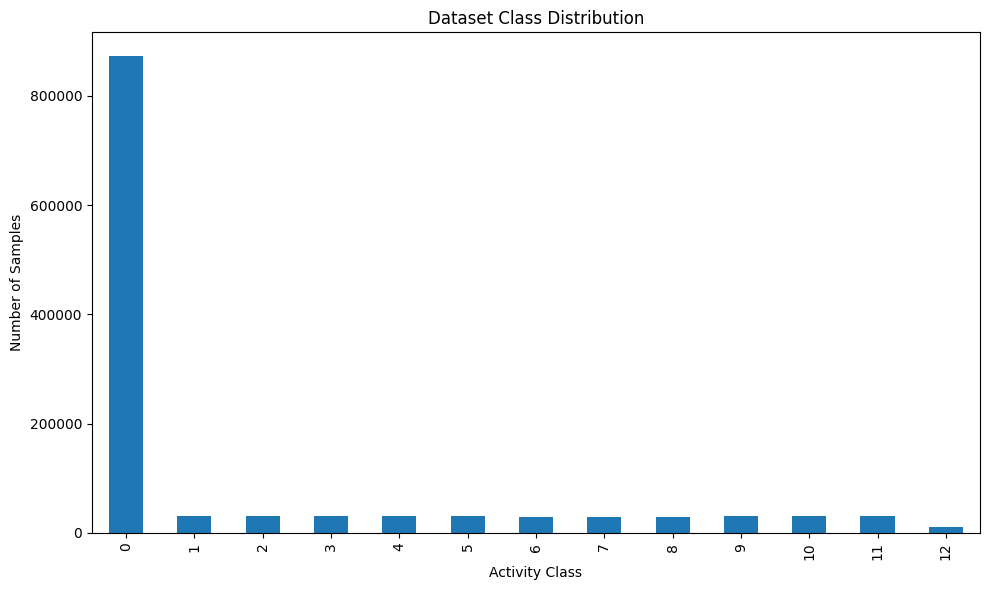

In [115]:
# FIG1: dataset class distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

class_distribution.plot(kind='bar')

plt.xlabel("Activity Class")
plt.ylabel("Number of Samples")

plt.title("Dataset Class Distribution")

plt.tight_layout()

plt.savefig(
    "FIG01_CLASS_DISTRIBUTION.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [116]:
# missing + infinite values

print("Missing Values:\n")
print(df.isnull().sum())

print("\nInfinite Values:\n")
print(np.isinf(df.select_dtypes(include=np.number)).sum())

Missing Values:

alx         0
aly         0
alz         0
glx         0
gly         0
glz         0
arx         0
ary         0
arz         0
grx         0
gry         0
grz         0
Activity    0
subject     0
dtype: int64

Infinite Values:

alx         0
aly         0
alz         0
glx         0
gly         0
glz         0
arx         0
ary         0
arz         0
grx         0
gry         0
grz         0
Activity    0
dtype: int64


In [117]:
# data cleaning + saving clean data

#replacing infinity with null and then droping null

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)
print("Cleaned Shape:", df.shape)

df.to_csv("CLEANED_DATA.csv", index=False)
print("CLEANED_DATA.csv saved")

Cleaned Shape: (1215745, 14)
CLEANED_DATA.csv saved


In [118]:
#creating DATASET_PROFILE.csv

profile = {
    "Total Samples": [len(df)],
    "Total Features": [df.shape[1] - 2],
    "Subjects": [df['subject'].nunique()],
    "Activities": [len(df['Activity'].unique()) - 1],
    "Sampling Rate (Hz)": [50],
    "Window Size": [128],
    "Overlap": ["50%"]
}

profile_df = pd.DataFrame(profile)
print("\n",profile_df)

profile_df.to_csv("DATASET_PROFILE.csv", index=False)
print("\nDATASET_PROFILE.csv saved")




    Total Samples  Total Features  Subjects  Activities  Sampling Rate (Hz)  \
0        1215745              12        10          12                  50   

   Window Size Overlap  
0          128     50%  

DATASET_PROFILE.csv saved


In [119]:
WINDOW_SIZE = 128
OVERLAP = 64
THRESHOLD = 0.80

128 samples = 2.56 sec  
64 overlap = 50%

80% class consistency

In [120]:
# excluding activity and subject
sensor_columns = [
    'alx', 'aly', 'alz',
    'glx', 'gly', 'glz',
    'arx', 'ary', 'arz',
    'grx', 'gry', 'grz'
]

# Windowing Illustration (FIG3)

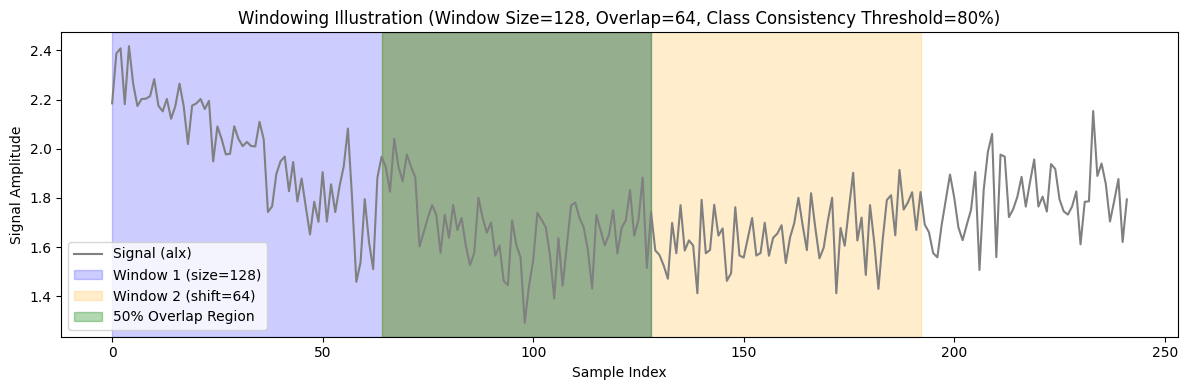

In [121]:
# FIG3: windowing Illustration (window lengt.... 50% Overlap.... class consistency threshold)

import matplotlib.pyplot as plt

sample_subject = df['subject'].unique()[0]

sample_signal = df[
    df['subject'] == sample_subject
]['alx'].values[:WINDOW_SIZE + OVERLAP + 50]

plt.figure(figsize=(12,4))

plt.plot(sample_signal, color='gray', label='Signal (alx)')

# window 1
w1_start, w1_end = 0, WINDOW_SIZE

# window 2 (shifted by OVERLAP => 50% overlap with window 1)
w2_start, w2_end = OVERLAP, OVERLAP + WINDOW_SIZE

plt.axvspan(
    w1_start, w1_end,
    color='blue', alpha=0.2,
    label=f'Window 1 (size={WINDOW_SIZE})'
)

plt.axvspan(
    w2_start, w2_end,
    color='orange', alpha=0.2,
    label=f'Window 2 (shift={OVERLAP})'
)

plt.axvspan(
    w2_start, w1_end,
    color='green', alpha=0.3,
    label='50% Overlap Region'
)

plt.xlabel("Sample Index")
plt.ylabel("Signal Amplitude")

plt.title(
    f"Windowing Illustration "
    f"(Window Size={WINDOW_SIZE}, Overlap={OVERLAP}, "
    f"Class Consistency Threshold={int(THRESHOLD*100)}%)"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "FIG03_WINDOWING_ILLUSTRATION.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [122]:
#windowing function

windows = []
labels = []
subjects = []

for subject in df['subject'].unique():

    subject_data = df[df['subject'] == subject]

    for start in range(0, len(subject_data) - WINDOW_SIZE, OVERLAP):

        end = start + WINDOW_SIZE

        window = subject_data.iloc[start:end]

        activity_counts = Counter(window['Activity'])

        dominant_activity = activity_counts.most_common(1)[0][0]

        dominance = activity_counts[dominant_activity] / WINDOW_SIZE

        if dominance >= THRESHOLD:

            sensor_window = window[sensor_columns].values

            windows.append(sensor_window)

            labels.append(dominant_activity)

            subjects.append(subject)

In [123]:
print("Total Windows:", len(windows))

print("Window Shape:", windows[0].shape)

print("First Label:", labels[0])

Total Windows: 18709
Window Shape: (128, 12)
First Label: 0


# Raw Signal Example per Class (FIG2)

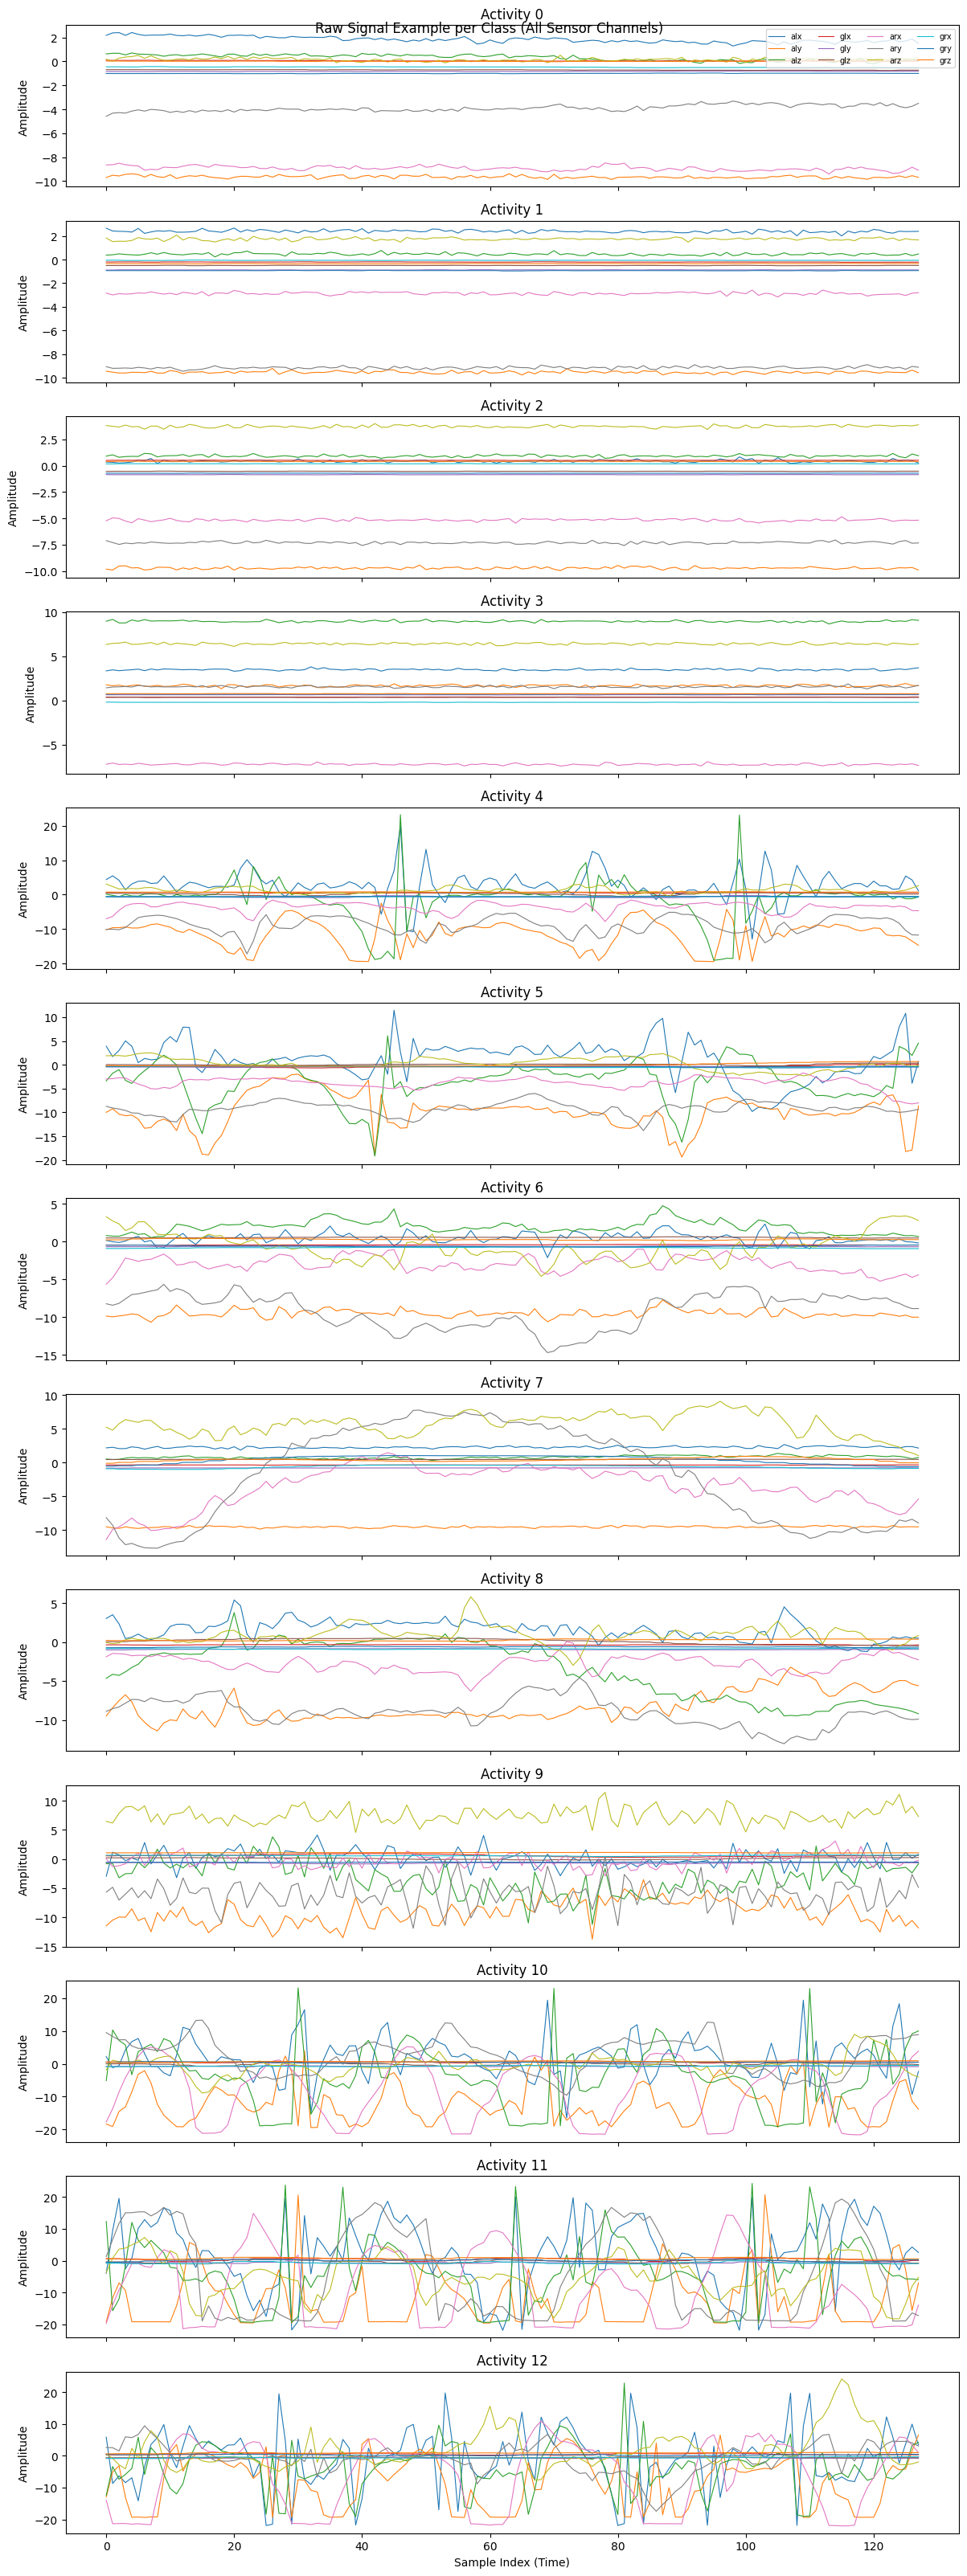

In [124]:
# FIG2: raw signal example per class

import matplotlib.pyplot as plt

unique_activities_raw = sorted(set(labels))

fig, axes = plt.subplots(
    len(unique_activities_raw), 1,
    figsize=(12, 2.5*len(unique_activities_raw)),
    sharex=True
)

for ax, activity in zip(axes, unique_activities_raw):

    idx = labels.index(activity)

    window = windows[idx]

    for ch, sensor_name in enumerate(sensor_columns):

        ax.plot(window[:, ch], label=sensor_name, linewidth=0.8)

    ax.set_ylabel("Amplitude")
    ax.set_title(f"Activity {activity}")

axes[-1].set_xlabel("Sample Index (Time)")

axes[0].legend(loc='upper right', ncol=4, fontsize=7)

plt.suptitle("Raw Signal Example per Class (All Sensor Channels)")

plt.tight_layout()

plt.savefig(
    "FIG02_RAW_SIGNAL_PER_CLASS.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [125]:
# windowed df
flattened_windows = []

for i, window in enumerate(windows):

    flattened = window.flatten()

    row = list(flattened)

    row.append(labels[i])

    row.append(subjects[i])

    flattened_windows.append(row)

# define cols
    columns = []

for t in range(WINDOW_SIZE):

    for sensor in sensor_columns:

        columns.append(f"{sensor}_{t}")

columns.append("Activity")
columns.append("subject")

# Create the windowed_df DataFrame
windowed_df = pd.DataFrame(flattened_windows, columns=columns)

print("\n")
windowed_df.to_csv("WINDOWED_DATA.csv", index=False)
print("WINDOWED_DATA.csv saved")



WINDOWED_DATA.csv saved


In [126]:
windowed_df.head()

,alx_0,aly_0,alz_0,glx_0,gly_0,glz_0,arx_0,ary_0,arz_0,grx_0,...,gly_127,glz_127,arx_127,ary_127,arz_127,grx_127,gry_127,grz_127,Activity,subject
0,2.1849,-9.6967,0.63077,0.103900,-0.84053,-0.68762,-8.6499,-4.5781,0.187760,-0.44902,...,-0.81614,-0.72888,-9.0845,-3.4969,0.31474,-0.51176,-1.00210,0.028017,0,subject1
1,1.9681,-9.6492,0.42264,0.046382,-0.84053,-0.68959,-8.8342,-3.9288,0.116060,-0.45294,...,-0.81238,-0.72299,-9.0635,-3.6101,-0.01384,-0.50196,-0.99589,0.023707,0,subject1
2,1.7424,-9.8604,0.09732,0.031540,-0.80863,-0.73084,-9.1148,-3.8489,0.109640,-0.51176,...,-0.85741,-0.69155,-9.0236,-4.0320,-0.20160,-0.48039,-0.95688,-0.237070,0,subject1
3,1.8242,-9.7103,0.26190,0.037106,-0.81238,-0.72299,-8.9949,-3.6794,0.055611,-0.50196,...,-0.85553,-0.67976,-8.8700,-4.0532,-0.31724,-0.47451,-0.95688,-0.260780,0,subject1
4,1.6121,-9.4981,0.68705,0.025974,-0.85741,-0.69155,-9.0269,-3.9346,-0.457150,-0.48039,...,-0.85929,-0.66601,-8.8980,-3.7648,-0.47991,-0.49608,-0.95483,-0.247840,0,subject1


In [127]:
# convert to json

json_data = []

for i in range(len(windows)):

    # Extract the numeric part of the subject string and convert to int
    subject_id = int(subjects[i].replace('subject', ''))

    entry = {
        "window_id": i,
        "subject": subject_id,
        "activity": int(labels[i]),
        "data": windows[i].tolist()
    }

    json_data.append(entry)


with open("WINDOWED_DATA.json", "w") as f:
    json.dump(json_data, f)

print("WINDOWED_DATA.json saved")

WINDOWED_DATA.json saved




1. Imports
2. Time-Domain Feature Extraction
3. Create Feature Dataset
4. Min-Max Scaling
5. Standard Scaling
6. Robust Scaling
7. Save Feature Datasets

In [128]:
from scipy.stats import skew
from scipy.stats import kurtosis
from scipy.signal import find_peaks

In [129]:
#hjroth fun
def hjorth_parameters(signal):

    first_deriv = np.diff(signal)
    second_deriv = np.diff(first_deriv)

    var0 = np.var(signal)
    var1 = np.var(first_deriv)
    var2 = np.var(second_deriv)

    activity = var0

    mobility = np.sqrt(var1 / var0) if var0 != 0 else 0

    complexity = (
        np.sqrt(var2 / var1) / mobility
        if var1 != 0 and mobility != 0
        else 0
    )

    return activity, mobility, complexity

In [130]:
#time domain extraction
def extract_time_features(signal):

    mean = np.mean(signal)
    median = np.median(signal)

    std = np.std(signal)
    var = np.var(signal)

    minimum = np.min(signal)
    maximum = np.max(signal)

    value_range = maximum - minimum

    iqr = np.percentile(signal,75) - np.percentile(signal,25)

    mad = np.mean(np.abs(signal - mean))

    sk = skew(signal)

    kurt = kurtosis(signal)

    rms = np.sqrt(np.mean(signal**2))

    zcr = np.sum(np.diff(np.sign(signal)) != 0)

    autocorr = np.corrcoef(signal[:-1], signal[1:])[0,1]

    sma = np.sum(np.abs(signal))

    energy = np.sum(signal**2)

    h_activity,h_mobility,h_complexity = hjorth_parameters(signal)

    peaks,_ = find_peaks(signal)

    peak_count = len(peaks)

    return [
        mean,
        median,
        std,
        var,
        minimum,
        maximum,
        value_range,
        iqr,
        mad,
        sk,
        kurt,
        rms,
        zcr,
        autocorr,
        sma,
        energy,
        h_activity,
        h_mobility,
        h_complexity,
        peak_count
    ]

In [131]:
#time domain features

sensor_columns = [
    'alx','aly','alz',
    'glx','gly','glz',
    'arx','ary','arz',
    'grx','gry','grz'
]

In [132]:
feature_rows = []

for idx,window in enumerate(windows):

    row = []

    for channel in range(window.shape[1]):

        signal = window[:,channel]

        row.extend(
            extract_time_features(signal)
        )

    row.append(labels[idx])

    feature_rows.append(row)

In [133]:
#col names
feature_names = [
    "mean",
    "median",
    "std",
    "var",
    "min",
    "max",
    "range",
    "iqr",
    "mad",
    "skew",
    "kurtosis",
    "rms",
    "zcr",
    "autocorr",
    "sma",
    "energy",
    "hj_activity",
    "hj_mobility",
    "hj_complexity",
    "peak_count"
]

In [134]:
columns = []

for sensor in sensor_columns:

    for feature in feature_names:

        columns.append(
            f"{sensor}_{feature}"
        )

columns.append("Activity")

In [135]:
#time feature dataset

time_df = pd.DataFrame(
    feature_rows,
    columns=columns
)

time_df.to_csv(
    "TIME_DOMAIN_FEATURES.csv",
    index=False
)

In [136]:
time_df.shape

(18709, 241)

# Feature Distribution Before Scaling (FIG4)

/tmp/ipykernel_2900/55342858.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=activities_sorted)
/tmp/ipykernel_2900/55342858.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=activities_sorted)
/tmp/ipykernel_2900/55342858.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=activities_sorted)
/tmp/ipykernel_2900/55342858.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=activities_sorted)


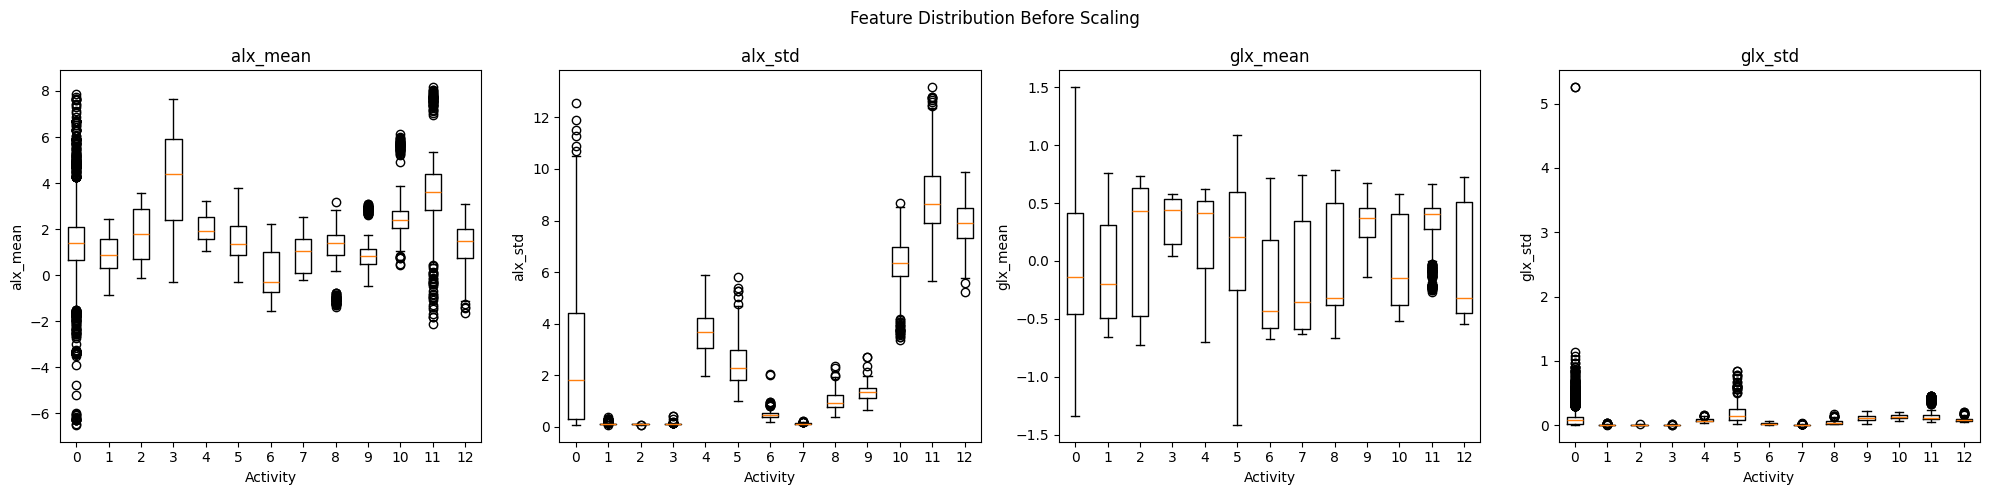

In [137]:
# FIG4: feature distribution before scaling

import matplotlib.pyplot as plt

selected_features = ['alx_mean', 'alx_std', 'glx_mean', 'glx_std']

activities_sorted = sorted(time_df['Activity'].unique())

fig, axes = plt.subplots(1, len(selected_features), figsize=(20,5))

for ax, feat in zip(axes, selected_features):

    data = [
        time_df[time_df['Activity'] == a][feat].values
        for a in activities_sorted
    ]

    ax.boxplot(data, labels=activities_sorted)

    ax.set_title(feat)
    ax.set_xlabel("Activity")
    ax.set_ylabel(feat)

plt.suptitle("Feature Distribution Before Scaling")

plt.tight_layout()

plt.savefig(
    "FIG04_FEATURE_DISTRIBUTION_BEFORE_SCALING.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()



12 sensor channels *
20 features per channel

= 240 features

   +1 Activity label
 = 241 columns

**Scaling**

1.   MinMax
2.   Standard
3.   Robust



In [138]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler

In [139]:
# seprate X and y
X = time_df.drop(
    "Activity",
    axis=1
)

y = time_df["Activity"]

In [140]:
minmax = MinMaxScaler()

X_minmax = minmax.fit_transform(X)

minmax_df = pd.DataFrame(
    X_minmax,
    columns=X.columns
)

minmax_df["Activity"] = y

minmax_df.to_csv(
    "SCALED_FEATURES_MINMAX.csv",
    index=False
)


In [141]:
standard = StandardScaler()

X_standard = standard.fit_transform(X)

standard_df = pd.DataFrame(
    X_standard,
    columns=X.columns
)

standard_df["Activity"] = y

standard_df.to_csv(
    "SCALED_FEATURES_STANDARD.csv",
    index=False
)

# Feature Distribution After Scaling (FIG5)

/tmp/ipykernel_2900/1675427371.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=activities_sorted)
/tmp/ipykernel_2900/1675427371.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=activities_sorted)
/tmp/ipykernel_2900/1675427371.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=activities_sorted)
/tmp/ipykernel_2900/1675427371.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=activities_

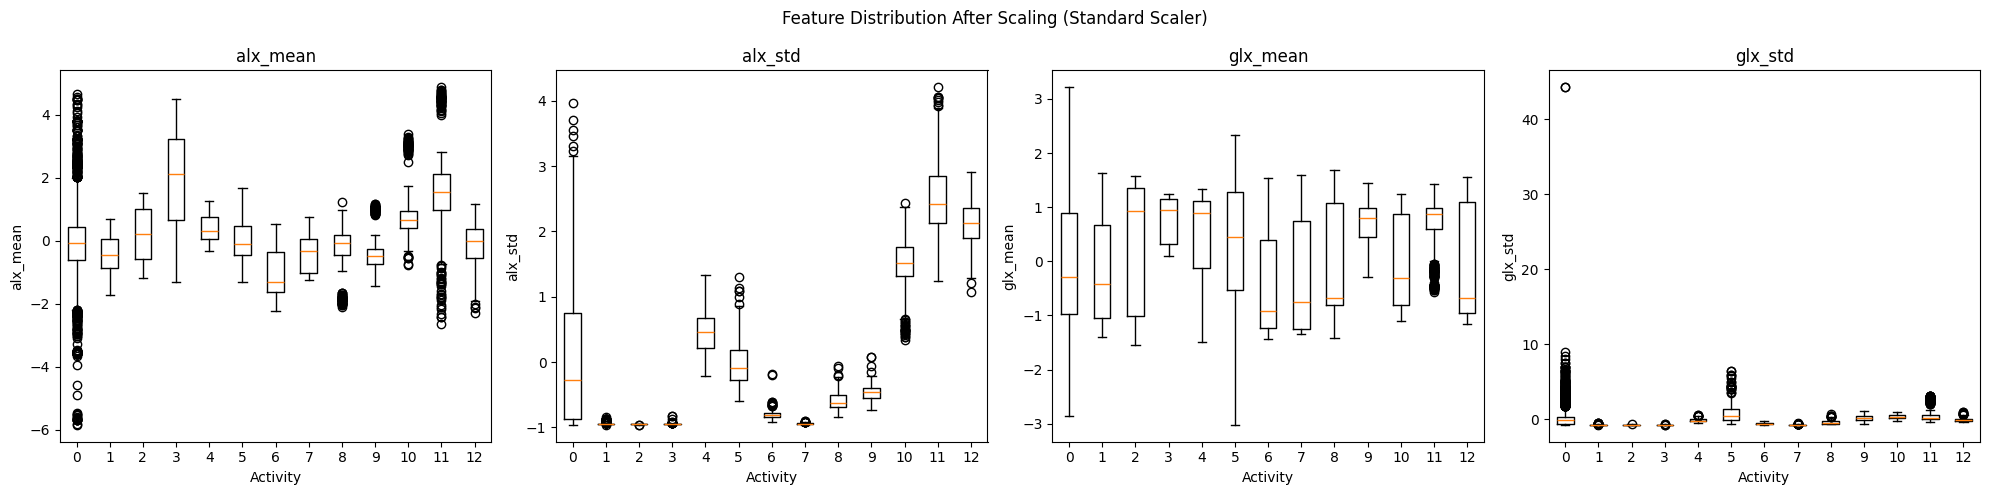

In [142]:
# FIG5: feature distribution after scaling => standard scaler


activities_sorted = sorted(standard_df['Activity'].unique())

fig, axes = plt.subplots(1, len(selected_features), figsize=(20,5))

for ax, feat in zip(axes, selected_features):

    data = [
        standard_df[standard_df['Activity'] == a][feat].values
        for a in activities_sorted
    ]

    ax.boxplot(data, labels=activities_sorted)

    ax.set_title(feat)
    ax.set_xlabel("Activity")
    ax.set_ylabel(feat)

plt.suptitle("Feature Distribution After Scaling (Standard Scaler)")

plt.tight_layout()

plt.savefig(
    "FIG05_FEATURE_DISTRIBUTION_AFTER_SCALING.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [143]:
robust = RobustScaler()

X_robust = robust.fit_transform(X)

robust_df = pd.DataFrame(
    X_robust,
    columns=X.columns
)

robust_df["Activity"] = y

robust_df.to_csv(
    "SCALED_FEATURES_ROBUST.csv",
    index=False
)

#Feature Selection, Dimensionality Reduction and Model Training

## Tasks

1. Feature Selection
   - Variance Threshold
   - Correlation Filtering
   - Mutual Information

2. Dimensionality Reduction
   - PCA
   - LDA

3. Model Training
   - KNN
   - Decision Tree
   - Random Forest
   - Naive Bayes
   - SVM
   - Logistic Regression
   - ANN (MLP)

4. Model Evaluation
   - Accuracy
   - Precision
   - Recall
   - F1-Score
   - Confusion Matrix

## Output Files

- FINAL_SELECTED_FEATURES.csv
- MODEL_RESULTS.csv

In [144]:
import pandas as pd
import numpy as np

from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix

In [145]:
df = pd.read_csv(
    "SCALED_FEATURES_STANDARD.csv"
)

df.shape

(18709, 241)

In [146]:
#split X y
X = df.drop(
    "Activity",
    axis=1
)

y = df["Activity"]

print(X.shape)
print(y.shape)

(18709, 240)
(18709,)


In [147]:
#feature selection (method 1) => Varience threshold
selector = VarianceThreshold(
    threshold=0.01
)

X_var = selector.fit_transform(X)

print(
    "Features after Variance Threshold:",
    X_var.shape[1]
)

Features after Variance Threshold: 240


In [148]:
#feature selection (method 2) => Corelation filtering
corr_matrix = X.corr().abs()

upper = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

drop_cols = [
    column
    for column in upper.columns
    if any(upper[column] > 0.95)
]

X_corr = X.drop(
    columns=drop_cols
)

print(
    "Features after Correlation Filter:",
    X_corr.shape[1]
)

Features after Correlation Filter: 161


In [149]:
#feature selection (method 3) => mutual info
mi = mutual_info_classif(
    X_corr,
    y,
    random_state=42
)

mi_scores = pd.Series(
    mi,
    index=X_corr.columns
)

selected_features = mi_scores.sort_values(
    ascending=False
).head(100)

X_final = X_corr[
    selected_features.index
]

print(
    "Final Features:",
    X_final.shape
)

Final Features: (18709, 100)


Features after Variance Threshold = 240

Features after Correlation Filter = 161

Final Features = (18709,100)

In [150]:
final_df = X_final.copy()

final_df["Activity"] = y

final_df.to_csv(
    "FINAL_SELECTED_FEATURES.csv",
    index=False
)

# Feature Selection Comparison (FIG6)

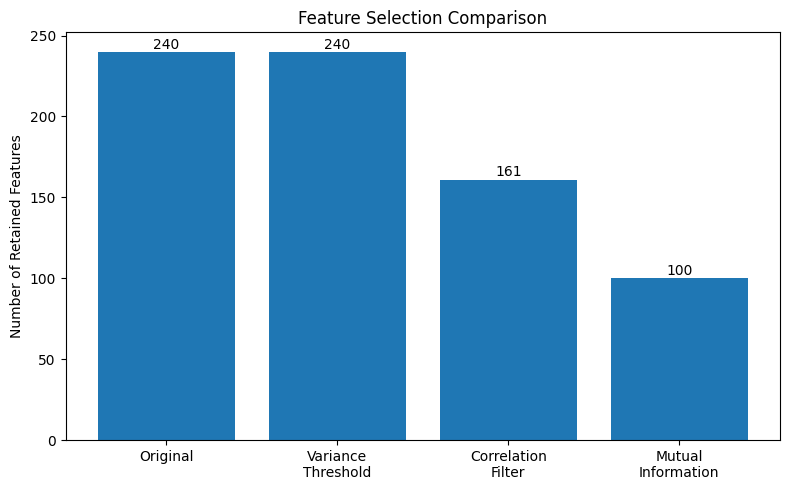

In [151]:
# FIG6: feature selection comparision

import matplotlib.pyplot as plt

feature_selection_counts = {
    "Original": X.shape[1],
    "Variance\nThreshold": X_var.shape[1],
    "Correlation\nFilter": X_corr.shape[1],
    "Mutual\nInformation": X_final.shape[1]
}

plt.figure(figsize=(8,5))

bars = plt.bar(
    feature_selection_counts.keys(),
    feature_selection_counts.values()
)

for bar, val in zip(bars, feature_selection_counts.values()):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        val + 2,
        str(val),
        ha='center'
    )

plt.ylabel("Number of Retained Features")
plt.title("Feature Selection Comparison")

plt.tight_layout()

plt.savefig(
    "FIG06_FEATURE_SELECTION_COMPARISON.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [152]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [153]:
# Components for 90%, 95%, 99%
pca = PCA()

pca.fit(X_final)

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

comp90 = np.argmax(
    cumulative_variance >= 0.90
) + 1

comp95 = np.argmax(
    cumulative_variance >= 0.95
) + 1

comp99 = np.argmax(
    cumulative_variance >= 0.99
) + 1

print("90% Variance:", comp90)
print("95% Variance:", comp95)
print("99% Variance:", comp99)


90% Variance: 21
95% Variance: 32
99% Variance: 58


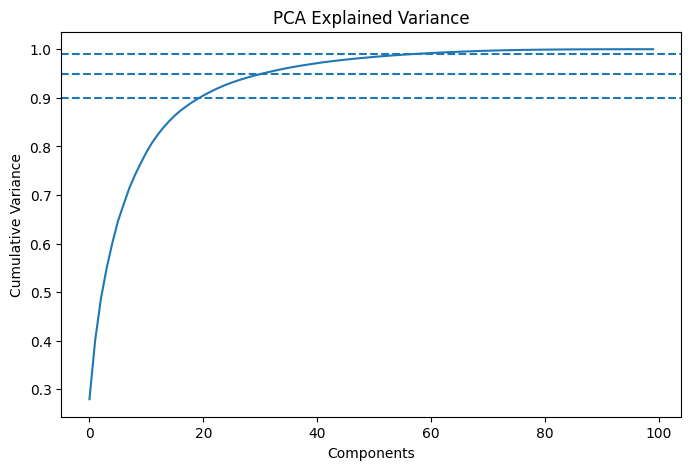

In [154]:
# pca plot
plt.figure(figsize=(8,5))

plt.plot(cumulative_variance)

plt.axhline(
    0.90,
    linestyle='--'
)

plt.axhline(
    0.95,
    linestyle='--'
)

plt.axhline(
    0.99,
    linestyle='--'
)

plt.xlabel("Components")
plt.ylabel("Cumulative Variance")

plt.title("PCA Explained Variance")

plt.show()


# PCA Results

| Variance Retained | Components |
|------------------|------------|
| 90% | 21 |
| 95% | 32 |
| 99% | 58 |

The 95% variance threshold was selected for model training, resulting in 32 principal components.

In [155]:
#pca dataset uses 95% variance
pca = PCA(
    n_components=comp95
)

X_pca = pca.fit_transform(
    X_final
)

print(X_pca.shape)

(18709, 32)


In [156]:
# LDA dataset
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [157]:
lda = LinearDiscriminantAnalysis()
X_lda = lda.fit_transform(
    X_final,
    y
)

print(X_lda.shape)

(18709, 12)


In [158]:
# Train test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_pca,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#Models required are
   - KNN
   - Decision Tree
   - Random Forest
   - Naive Bayes
   - SVM
   - Logistic Regression
   - ANN (MLP)

In [159]:
from sklearn.neighbors import KNeighborsClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.svm import SVC

from sklearn.linear_model import LogisticRegression

from sklearn.neural_network import MLPClassifier

In [160]:
#creating model dictionary
models = {

    "KNN":
        KNeighborsClassifier(),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ),

    "Naive Bayes":
        GaussianNB(),

    "SVM":
        SVC(),

    "Logistic Regression":
        LogisticRegression(
            max_iter=5000
        ),

    "ANN":
        MLPClassifier(
            hidden_layer_sizes=(100,),
            max_iter=500
        )
}

In [161]:
results = []

In [162]:
#training all models together

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_test
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average='macro'
    )

    recall = recall_score(
        y_test,
        predictions,
        average='macro'
    )

    f1 = f1_score(
        y_test,
        predictions,
        average='macro'
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

Training KNN...
Training Decision Tree...
Training Random Forest...
Training Naive Bayes...
Training SVM...
Training Logistic Regression...
Training ANN...


In [163]:
# result
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1"
    ]
)

results_df

,Model,Accuracy,Precision,Recall,F1
0,KNN,0.919294,0.814411,0.937154,0.869802
1,Decision Tree,0.881614,0.789092,0.806003,0.796609
2,Random Forest,0.918760,0.865681,0.860446,0.851654
3,Naive Bayes,0.807322,0.643485,0.911492,0.740842
4,SVM,0.907002,0.804671,0.898255,0.843738
5,Logistic Regression,0.890700,0.794175,0.844507,0.816509
6,ANN,0.926777,0.857598,0.901423,0.877633


In [164]:
results_df.to_csv(
    "MODEL_RESULTS.csv",
    index=False
)

In [165]:
# Best model

results_df.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1
6,ANN,0.926777,0.857598,0.901423,0.877633
0,KNN,0.919294,0.814411,0.937154,0.869802
2,Random Forest,0.918760,0.865681,0.860446,0.851654
4,SVM,0.907002,0.804671,0.898255,0.843738
5,Logistic Regression,0.890700,0.794175,0.844507,0.816509
1,Decision Tree,0.881614,0.789092,0.806003,0.796609
3,Naive Bayes,0.807322,0.643485,0.911492,0.740842


#ANN has the highest Accuracy

#Visualization and Advanced Features



1. PCA Explained Variance Plot
2. PCA 2D Visualization
3. Model Comparison Graph
4. Confusion Matrices
5. Spectral Feature Extraction (FFT)
6. Codebook Features

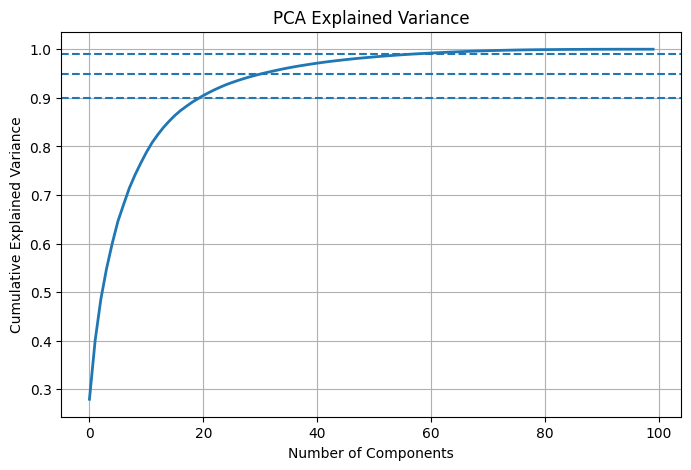

In [166]:
# PCA explained Varience (PCA Plot)

plt.figure(figsize=(8,5))

plt.plot(
    cumulative_variance,
    linewidth=2
)

plt.axhline(
    y=0.90,
    linestyle='--'
)

plt.axhline(
    y=0.95,
    linestyle='--'
)

plt.axhline(
    y=0.99,
    linestyle='--'
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")

plt.grid(True)

plt.savefig(
    "FIG07_PCA_EXPLAINED_VARIANCE.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [167]:
#PCA 2D visualization
pca2 = PCA(
    n_components=2
)

X_pca2 = pca2.fit_transform(
    X_final
)

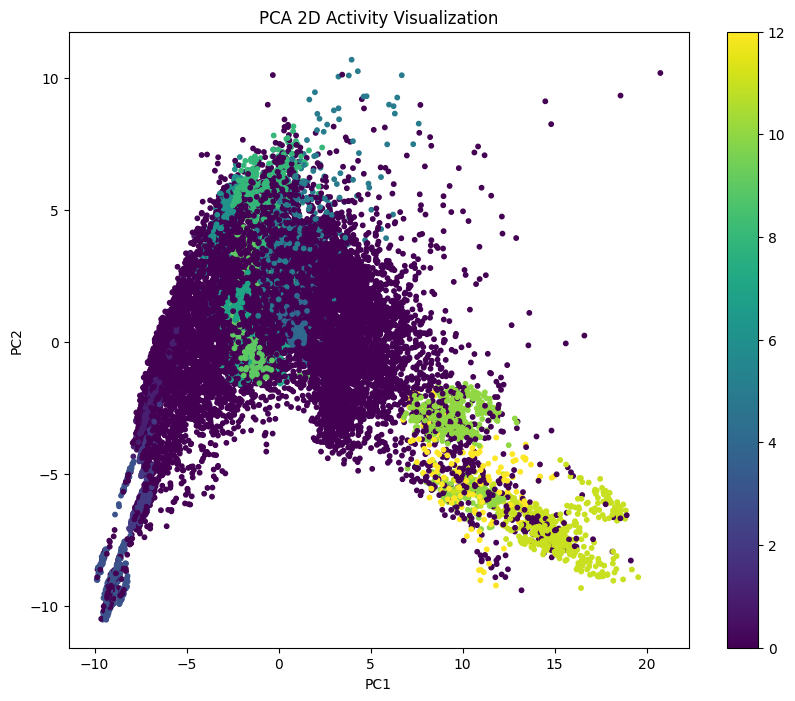

In [168]:
plt.figure(figsize=(10,8))

scatter = plt.scatter(
    X_pca2[:,0],
    X_pca2[:,1],
    c=y,
    s=10
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("PCA 2D Activity Visualization")

plt.colorbar(scatter)

plt.savefig(
    "FIG08_PCA_2D.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

#Model Comparison

In [169]:
results_df = pd.read_csv(
    "MODEL_RESULTS.csv"
)

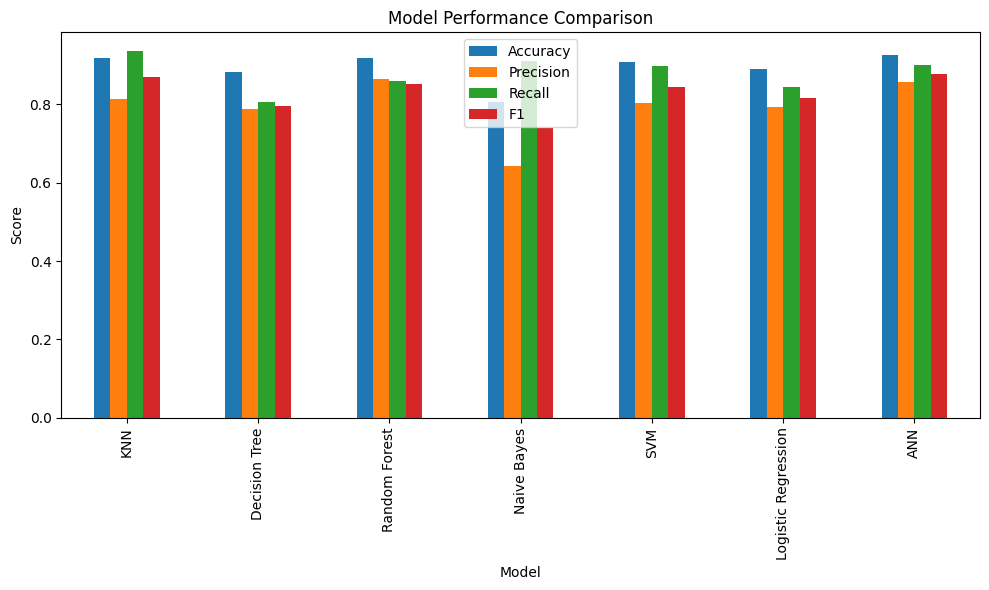

In [170]:
results_df.set_index(
    "Model"
)[
    ["Accuracy","Precision","Recall","F1"]
].plot(
    kind="bar",
    figsize=(10,6)
)

plt.title(
    "Model Performance Comparison"
)

plt.ylabel("Score")

plt.tight_layout()

plt.savefig(
    "FIG11_MODEL_COMPARISON.png",
    dpi=300
)

plt.show()

In [171]:
# Confusion Matrix for all Models

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

import matplotlib.pyplot as plt

In [172]:
models = {

    "KNN":
        KNeighborsClassifier(),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ),

    "Naive Bayes":
        GaussianNB(),

    "SVM":
        SVC(),

    "Logistic Regression":
        LogisticRegression(
            max_iter=5000
        ),

    "ANN":
        MLPClassifier(
            hidden_layer_sizes=(100,),
            max_iter=500,
            random_state=42
        )
}

Generating Confusion Matrix for KNN


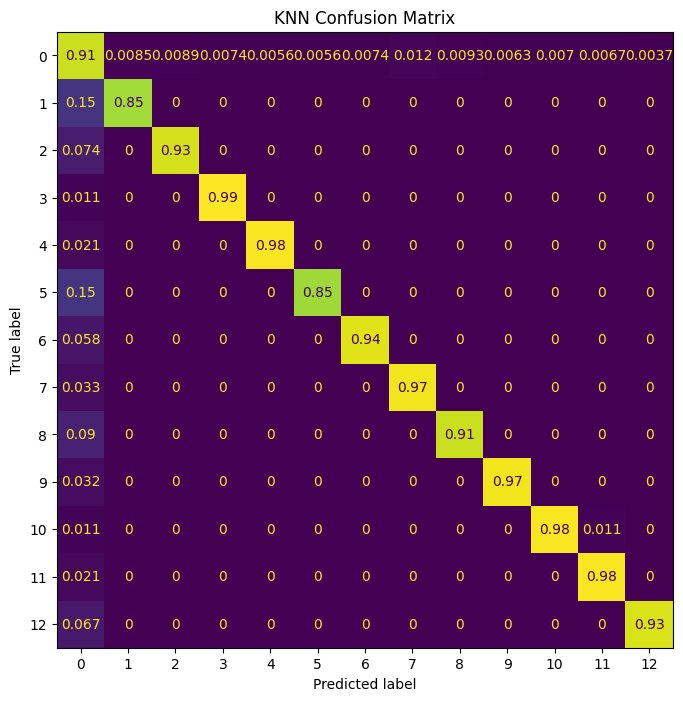

Generating Confusion Matrix for Decision Tree


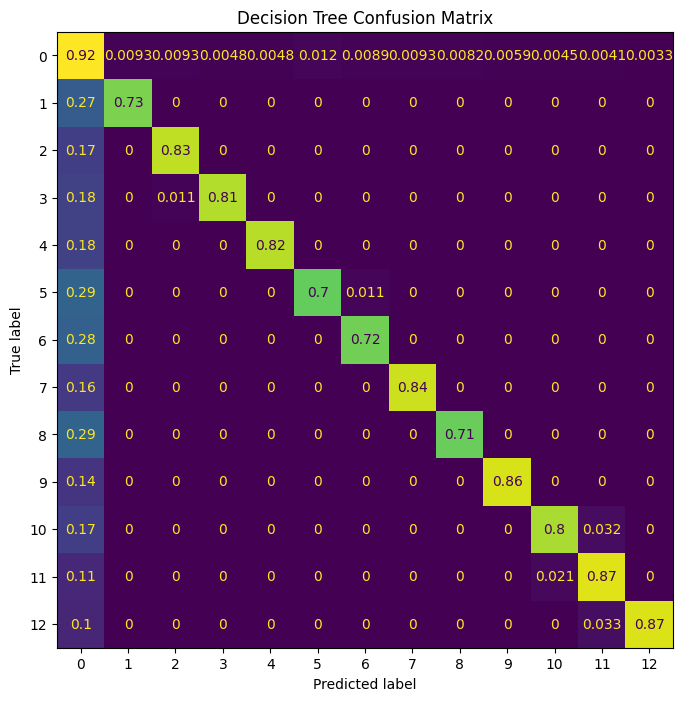

Generating Confusion Matrix for Random Forest


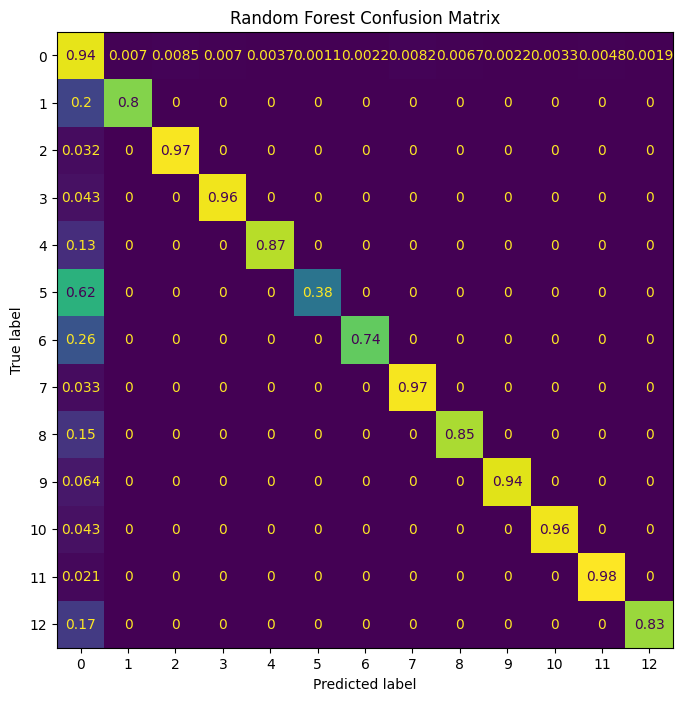

Generating Confusion Matrix for Naive Bayes


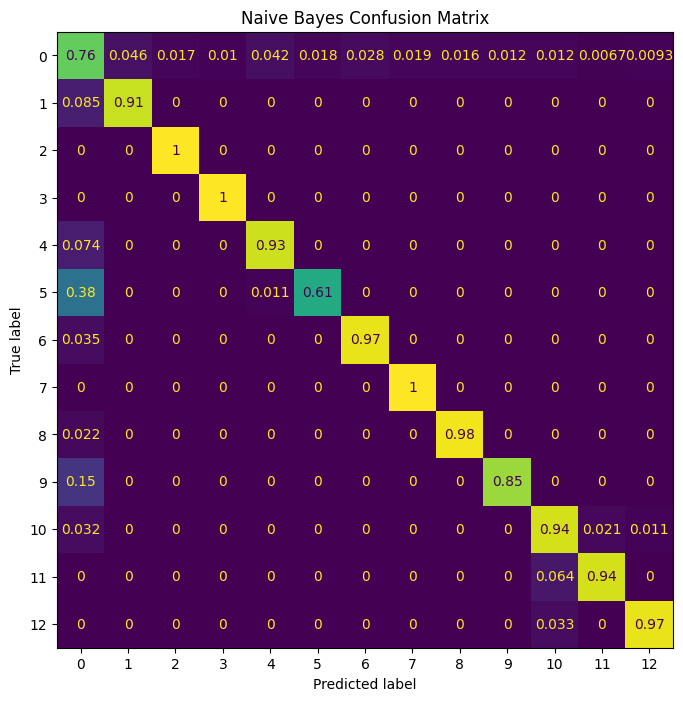

Generating Confusion Matrix for SVM


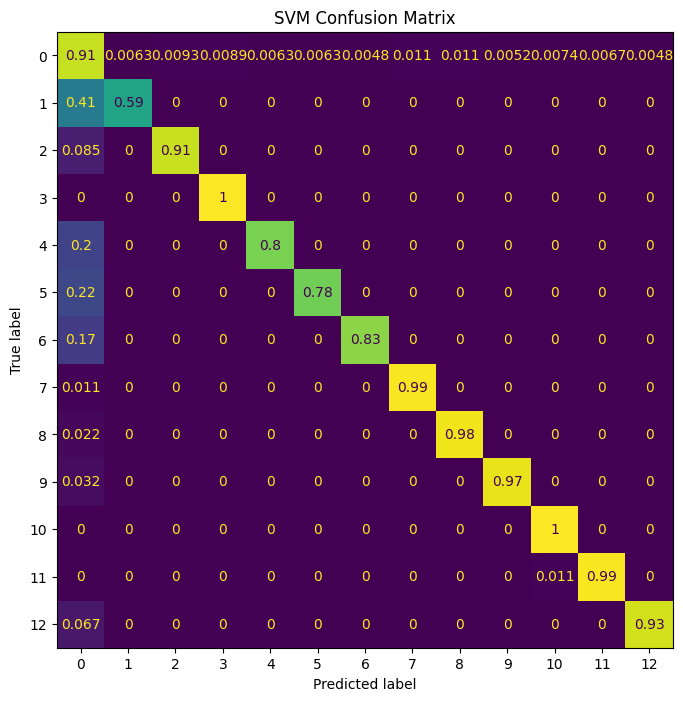

Generating Confusion Matrix for Logistic Regression


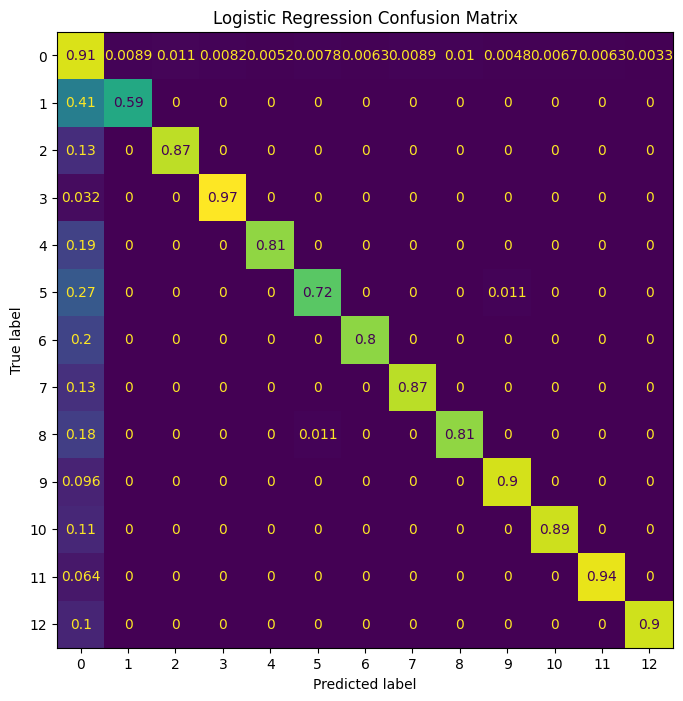

Generating Confusion Matrix for ANN


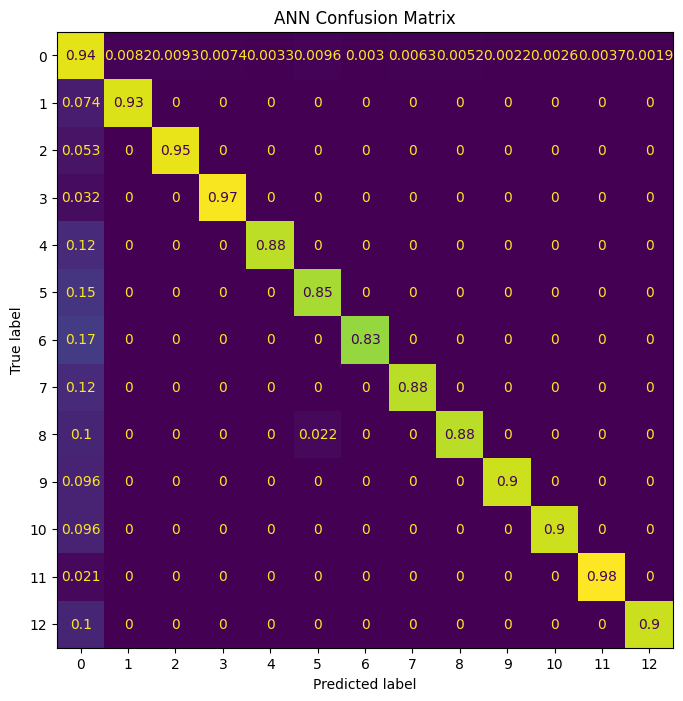

In [173]:
for name, model in models.items():

    print(f"Generating Confusion Matrix for {name}")

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_test
    )

    cm = confusion_matrix(
        y_test,
        predictions,
        normalize='true'
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm
    )

    fig, ax = plt.subplots(
        figsize=(8,8)
    )

    disp.plot(
        ax=ax,
        colorbar=False
    )

    plt.title(
        f"{name} Confusion Matrix"
    )

    plt.savefig(
        f"FIG12_{name.replace(' ','_')}_CONFUSION_MATRIX.png",
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

# Spectral Feature Extraction (FFT)



1. Apply Fast Fourier Transform (FFT)
2. Extract Frequency-Domain Features
3. Create Spectral Feature Dataset
4. Save SPECTRAL_FEATURES.csv

In [174]:
from scipy.fft import rfft
from scipy.fft import rfftfreq

from scipy.signal import find_peaks
from scipy.stats import entropy

In [175]:
#frequency sampling
FS = 50

In [176]:
#FFT feature Function
def extract_spectral_features(signal):

    fft_vals = np.abs(rfft(signal))

    freqs = rfftfreq(
        len(signal),
        d=1/FS
    )

    power = fft_vals**2

    spectral_energy = np.sum(power)

    spectral_entropy = entropy(
        power / (np.sum(power) + 1e-12)
    )

    spectral_centroid = (
        np.sum(freqs * power)
        /
        (np.sum(power) + 1e-12)
    )

    spectral_spread = np.sqrt(
        np.sum(
            ((freqs - spectral_centroid)**2)
            * power
        )
        /
        (np.sum(power) + 1e-12)
    )

    threshold = 0.85 * np.sum(power)

    cumulative = np.cumsum(power)

    spectral_rolloff = freqs[
        np.where(cumulative >= threshold)[0][0]
    ]

    spectral_flatness = (
        np.exp(
            np.mean(
                np.log(power + 1e-12)
            )
        )
        /
        np.mean(power)
    )

    dominant_freq = freqs[
        np.argmax(power)
    ]

    peaks, _ = find_peaks(power)

    peak_freqs = freqs[peaks]

    peak_freqs = np.sort(peak_freqs)[::-1]

    while len(peak_freqs) < 3:
        peak_freqs = np.append(
            peak_freqs,
            0
        )

    bandpower_0_5 = np.sum(
        power[
            (freqs >= 0)
            &
            (freqs < 5)
        ]
    )

    bandpower_5_10 = np.sum(
        power[
            (freqs >= 5)
            &
            (freqs < 10)
        ]
    )

    return [
        spectral_energy,
        spectral_entropy,
        spectral_centroid,
        spectral_spread,
        spectral_rolloff,
        spectral_flatness,
        dominant_freq,
        peak_freqs[0],
        peak_freqs[1],
        peak_freqs[2],
        bandpower_0_5,
        bandpower_5_10
    ]

In [177]:
#extract fft features
spectral_rows = []

for idx, window in enumerate(windows):

    row = []

    for channel in range(window.shape[1]):

        signal = window[:, channel]

        row.extend(
            extract_spectral_features(signal)
        )

    row.append(labels[idx])

    spectral_rows.append(row)

# Spectral Feature Examples (FIG9)

FFT magnitude spectrum for one representative window per activity (accelerometer channel `alx`).

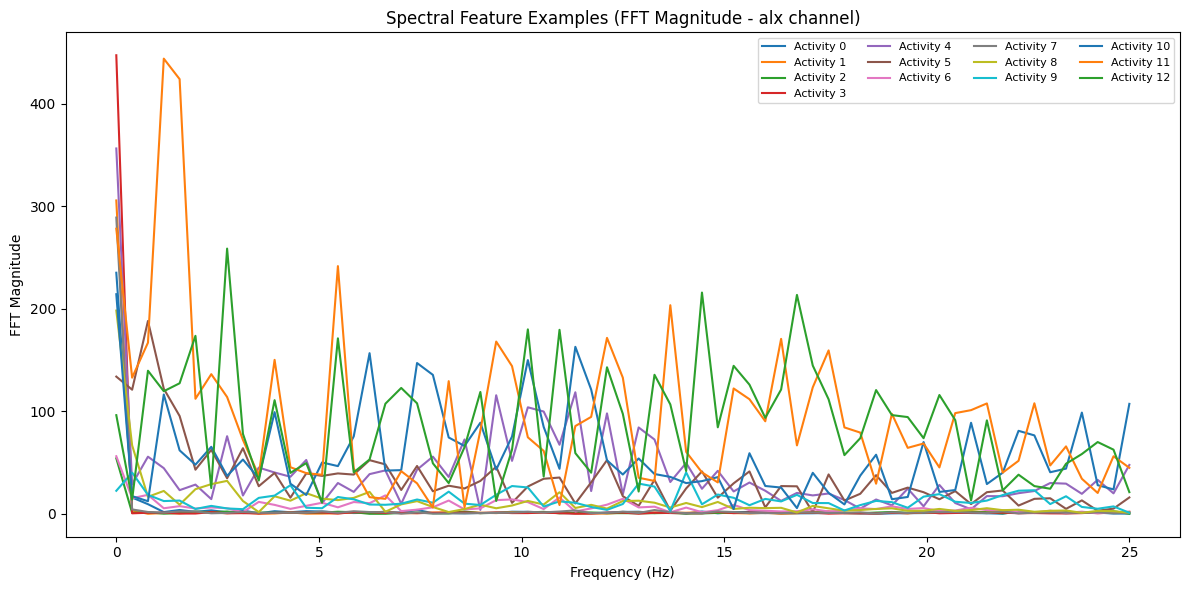

In [178]:
# FIG9: Spectral Feature Examples (FFT Magnitude per Activity)

unique_activities_spec = sorted(set(labels))

plt.figure(figsize=(12,6))

for activity in unique_activities_spec:

    idx = labels.index(activity)

    signal = windows[idx][:, 0]   # alx channel

    fft_vals = np.abs(rfft(signal))

    freqs = rfftfreq(
        len(signal),
        d=1/FS
    )

    plt.plot(freqs, fft_vals, label=f"Activity {activity}")

plt.xlabel("Frequency (Hz)")
plt.ylabel("FFT Magnitude")

plt.title("Spectral Feature Examples (FFT Magnitude - alx channel)")

plt.legend(ncol=4, fontsize=8)

plt.tight_layout()

plt.savefig(
    "FIG09_SPECTRAL_FFT_EXAMPLES.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [179]:
#cols
spectral_names = [

    "energy",
    "entropy",
    "centroid",
    "spread",
    "rolloff",
    "flatness",
    "dominant_freq",
    "peak1",
    "peak2",
    "peak3",
    "bandpower_0_5",
    "bandpower_5_10"
]

columns = []

for sensor in sensor_columns:

    for feature in spectral_names:

        columns.append(
            f"{sensor}_{feature}"
        )

columns.append("Activity")



In [180]:
#create dataset
spectral_df = pd.DataFrame(
    spectral_rows,
    columns=columns
)

spectral_df.shape

spectral_df.to_csv(
    "SPECTRAL_FEATURES.csv",
    index=False
)

#Training models on Spectral Dataset


In [181]:
# X_spectral y_spectral split
X_spec = spectral_df.drop(
    "Activity",
    axis=1
)

y_spec = spectral_df["Activity"]

In [182]:
from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.svm import SVC

from sklearn.linear_model import LogisticRegression

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score


In [183]:
#standard scaling
scaler = StandardScaler()

X_spec_scaled = scaler.fit_transform(
    X_spec
)

In [184]:
#pca
pca = PCA(
    n_components=0.95
)

X_spec_pca = pca.fit_transform(
    X_spec_scaled
)

print(
    "PCA Shape:",
    X_spec_pca.shape
)

print(
    "Components Used:",
    pca.n_components_
)

PCA Shape: (18709, 63)
Components Used: 63


# Spectral PCA Visualizations

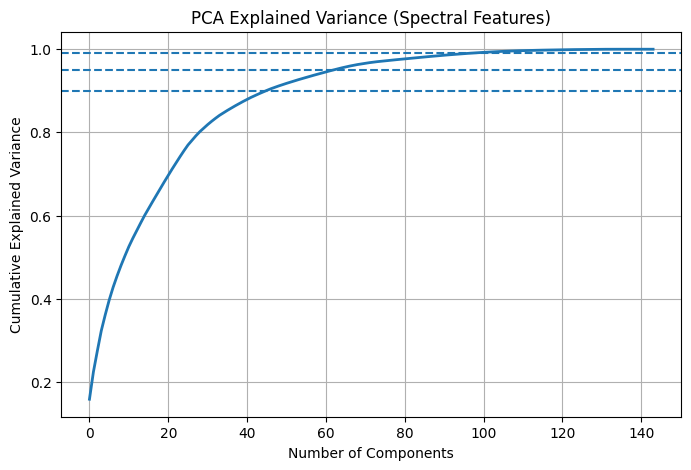

In [185]:
# Spectral pca explained variance plot

pca_spec_full = PCA()
pca_spec_full.fit(X_spec_scaled)

cumulative_variance_spec = np.cumsum(
    pca_spec_full.explained_variance_ratio_
)

plt.figure(figsize=(8,5))

plt.plot(
    cumulative_variance_spec,
    linewidth=2
)

plt.axhline(y=0.90, linestyle='--')
plt.axhline(y=0.95, linestyle='--')
plt.axhline(y=0.99, linestyle='--')

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance (Spectral Features)")

plt.grid(True)

plt.savefig(
    "FIG07_SPECTRAL_PCA_EXPLAINED_VARIANCE.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


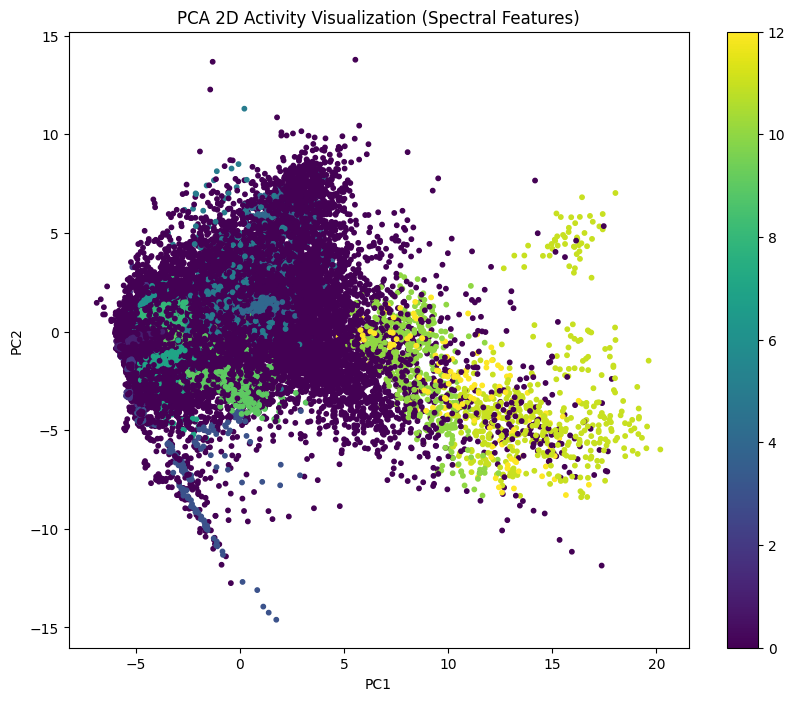

In [186]:
# Spectral PCA 2D Visualization

pca2_spec = PCA(n_components=2)

X_spec_pca2 = pca2_spec.fit_transform(X_spec_scaled)

plt.figure(figsize=(10,8))

scatter = plt.scatter(
    X_spec_pca2[:,0],
    X_spec_pca2[:,1],
    c=y_spec,
    s=10
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("PCA 2D Activity Visualization (Spectral Features)")

plt.colorbar(scatter)

plt.savefig(
    "FIG08_SPECTRAL_PCA_2D.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [187]:
X_train, X_test, y_train, y_test = train_test_split(
    X_spec_pca,
    y_spec,
    test_size=0.20,
    random_state=42,
    stratify=y_spec
)

In [188]:
#model dictionary
models = {

    "KNN":
        KNeighborsClassifier(),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ),

    "Naive Bayes":
        GaussianNB(),

    "SVM":
        SVC(),

    "Logistic Regression":
        LogisticRegression(
            max_iter=5000
        ),

    "ANN":
        MLPClassifier(
            hidden_layer_sizes=(100,),
            max_iter=500,
            random_state=42
        )
}

In [189]:
results = []

fitted_models_spec = {}

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(
        X_train,
        y_train
    )

    fitted_models_spec[name] = model

    predictions = model.predict(
        X_test
    )

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average='macro'
    )

    recall = recall_score(
        y_test,
        predictions,
        average='macro'
    )

    f1 = f1_score(
        y_test,
        predictions,
        average='macro'
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])


Training KNN...
Training Decision Tree...
Training Random Forest...
Training Naive Bayes...
Training SVM...


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Training Logistic Regression...
Training ANN...


In [190]:
spectral_results = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1"
    ]
)

spectral_results = spectral_results.sort_values(
    by="Accuracy",
    ascending=False
)

spectral_results

,Model,Accuracy,Precision,Recall,F1
6,ANN,0.870390,0.789642,0.750420,0.768211
2,Random Forest,0.864244,0.853947,0.652329,0.698553
4,SVM,0.845537,0.679127,0.641240,0.637125
5,Logistic Regression,0.838856,0.719113,0.696256,0.702648
0,KNN,0.831908,0.686756,0.736753,0.702975
1,Decision Tree,0.809193,0.663135,0.666303,0.663493
3,Naive Bayes,0.629610,0.484711,0.823272,0.580010


In [191]:
spectral_results.to_csv(
    "SPECTRAL_MODEL_RESULTS.csv",
    index=False
)

# Spectral Model Comparison & Confusion Matrices

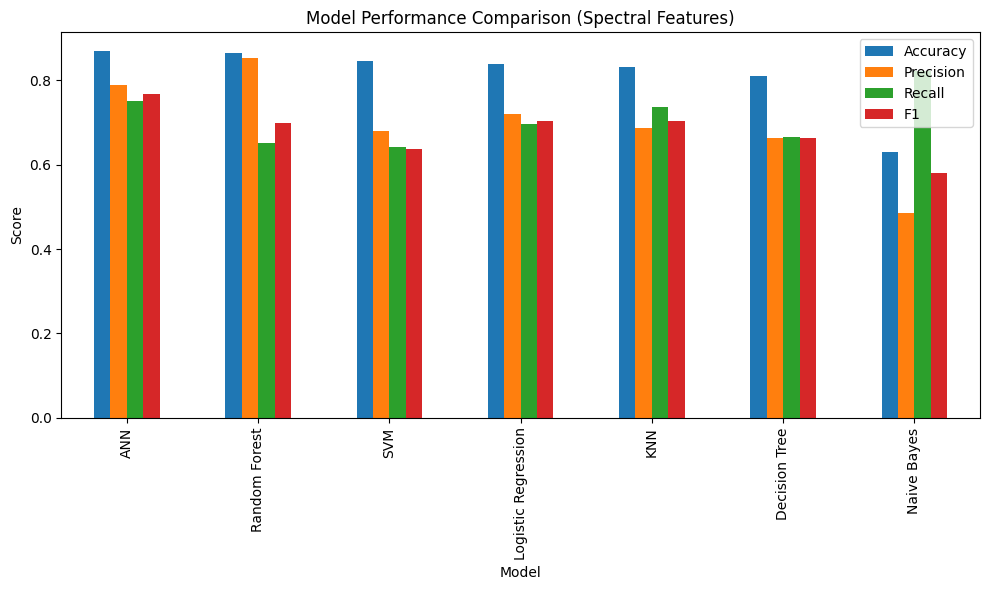

In [192]:
# Spectral Model Comparison Plot

spectral_results_sorted = spectral_results.sort_values(
    by="Accuracy",
    ascending=False
)

spectral_results_sorted.set_index(
    "Model"
)[
    ["Accuracy","Precision","Recall","F1"]
].plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Model Performance Comparison (Spectral Features)")

plt.ylabel("Score")

plt.tight_layout()

plt.savefig(
    "FIG11_SPECTRAL_MODEL_COMPARISON.png",
    dpi=300
)

plt.show()


Generating Confusion Matrix for KNN (Spectral)


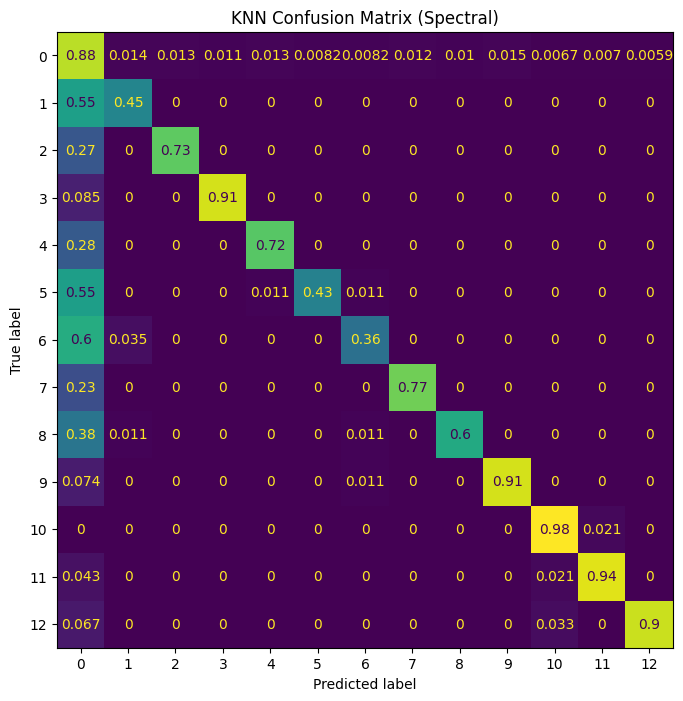

Generating Confusion Matrix for Decision Tree (Spectral)


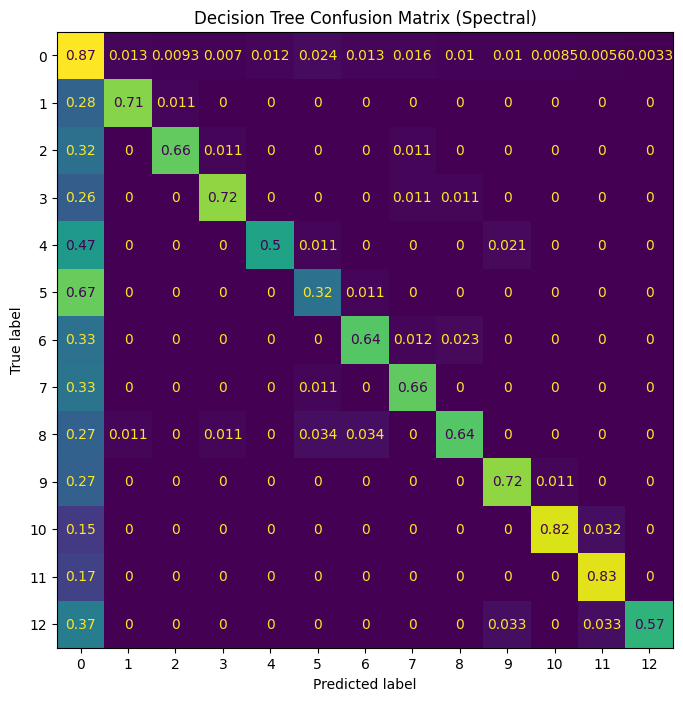

Generating Confusion Matrix for Random Forest (Spectral)


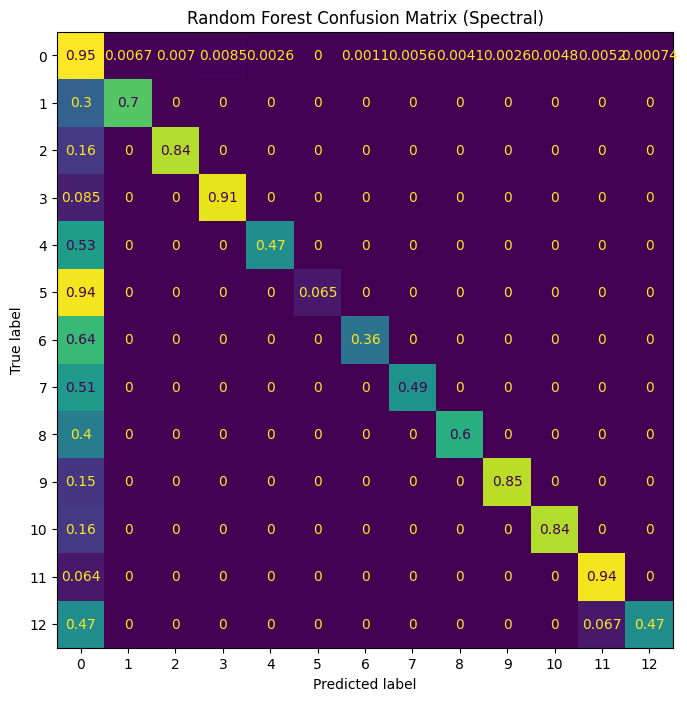

Generating Confusion Matrix for Naive Bayes (Spectral)


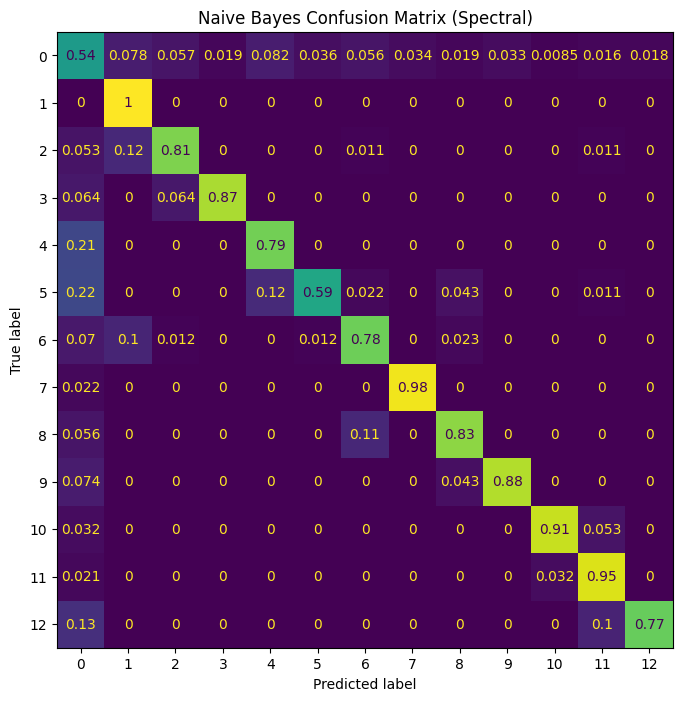

Generating Confusion Matrix for SVM (Spectral)


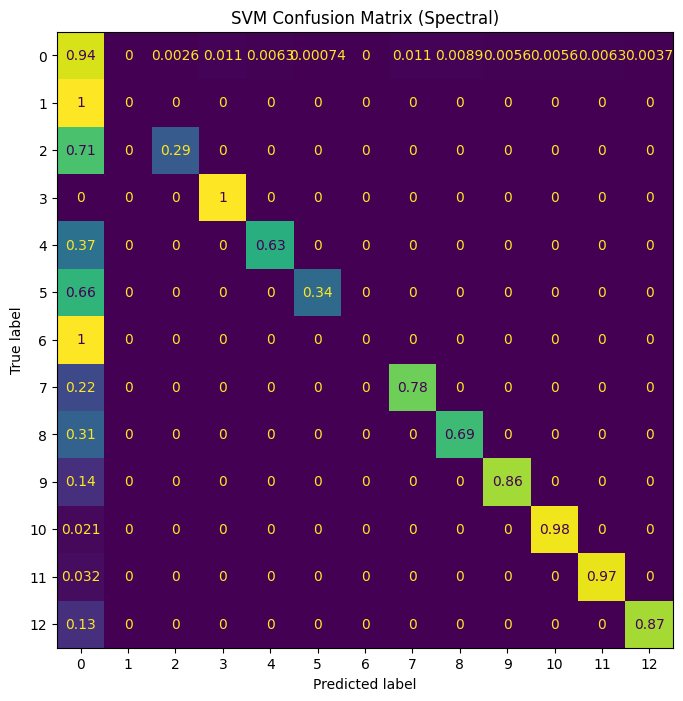

Generating Confusion Matrix for Logistic Regression (Spectral)


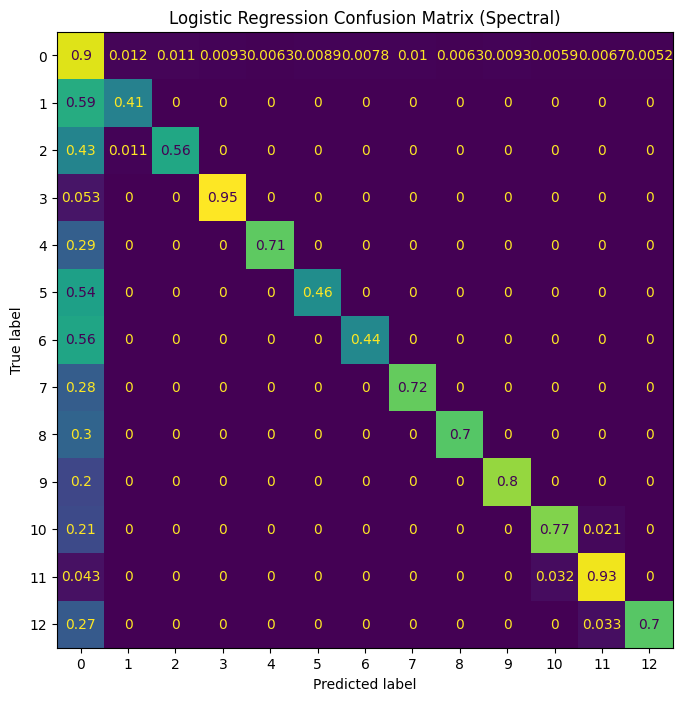

Generating Confusion Matrix for ANN (Spectral)


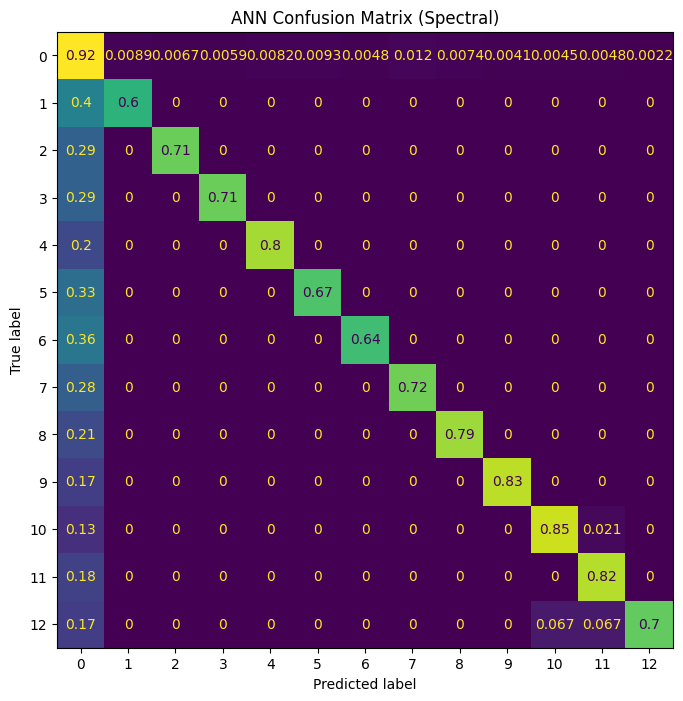

In [193]:
# Spectral Confusion Matrices for all Models

for name, model in fitted_models_spec.items():

    print(f"Generating Confusion Matrix for {name} (Spectral)")

    predictions = model.predict(
        X_test
    )

    cm = confusion_matrix(
        y_test,
        predictions,
        normalize='true'
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm
    )

    fig, ax = plt.subplots(
        figsize=(8,8)
    )

    disp.plot(
        ax=ax,
        colorbar=False
    )

    plt.title(
        f"{name} Confusion Matrix (Spectral)"
    )

    plt.savefig(
        f"FIG12_SPECTRAL_{name.replace(' ','_')}_CONFUSION_MATRIX.png",
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()


In [194]:
best_model = spectral_results.iloc[0]

print("Best Spectral Model")
print(best_model)

Best Spectral Model
Model             ANN
Accuracy      0.87039
Precision    0.789642
Recall        0.75042
F1           0.768211
Name: 6, dtype: object


# Codebook Features

## Tasks

1. Generate Visual Words using MiniBatchKMeans
2. Create Histogram Representation
3. Train Classifiers
4. Compare Results

In [195]:
from sklearn.cluster import MiniBatchKMeans

In [196]:
X_codebook = X_pca

In [197]:
kmeans = MiniBatchKMeans(
    n_clusters=32,
    random_state=42
)

kmeans.fit(X_codebook)

MiniBatchKMeans(n_clusters=32, random_state=42)

In [198]:
#assign each window

cluster_labels = kmeans.predict(
    X_codebook
)

In [199]:
#dataset

codebook_df = pd.DataFrame({

    "cluster_id": cluster_labels,
    "Activity": y.values
})

codebook_df.to_csv(
    "CODEBOOK_FEATURES.csv",
    index=False
)

# Codebook PCA 2D Visualization


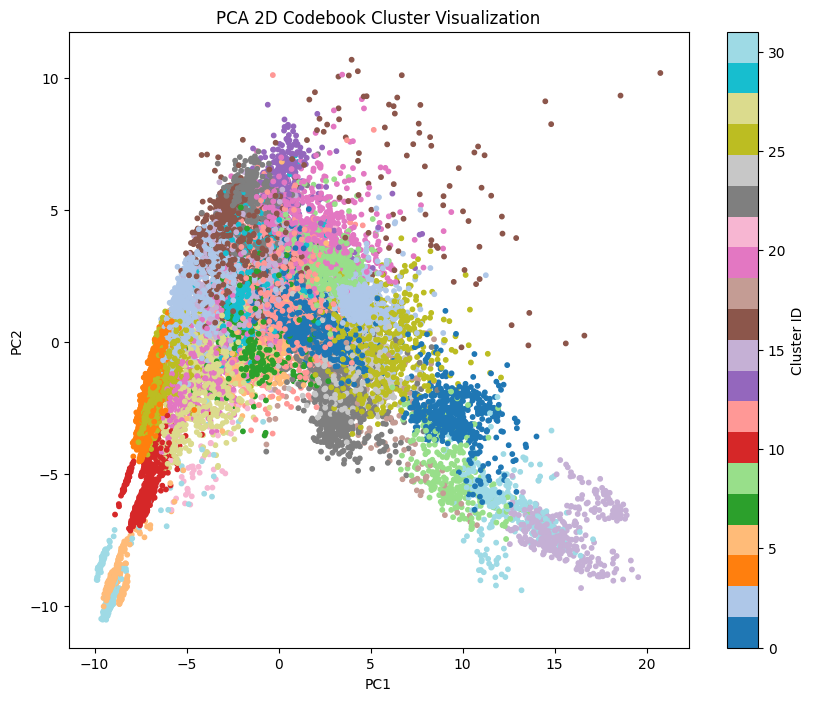

In [200]:
# Codebook PCA 2D Visualization colored by Cluster ID

pca2_cb = PCA(n_components=2)

X_cb_pca2 = pca2_cb.fit_transform(X_codebook)

plt.figure(figsize=(10,8))

scatter = plt.scatter(
    X_cb_pca2[:,0],
    X_cb_pca2[:,1],
    c=cluster_labels,
    cmap='tab20',
    s=10
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("PCA 2D Codebook Cluster Visualization")

plt.colorbar(scatter, label="Cluster ID")

plt.savefig(
    "FIG08_CODEBOOK_PCA_2D.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


#Training Models Again

In [201]:
from sklearn.model_selection import train_test_split

X_cb = codebook_df[["cluster_id"]]
y_cb = codebook_df["Activity"]

X_train, X_test, y_train, y_test = train_test_split(
    X_cb,
    y_cb,
    test_size=0.20,
    random_state=42,
    stratify=y_cb
)

In [202]:
    #model dictionary
models = {

    "KNN":
        KNeighborsClassifier(),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ),

    "Naive Bayes":
        GaussianNB(),

    "SVM":
        SVC(),

    "Logistic Regression":
        LogisticRegression(
            max_iter=5000
        ),

    "ANN":
        MLPClassifier(
            hidden_layer_sizes=(100,),
            max_iter=500,
            random_state=42
        )
}


In [203]:
results = []

fitted_models_cb = {}

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train, y_train)

    fitted_models_cb[name] = model

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test,
        predictions,
        average='macro'
    )

    recall = recall_score(
        y_test,
        predictions,
        average='macro'
    )

    f1 = f1_score(
        y_test,
        predictions,
        average='macro'
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])


Training KNN...
Training Decision Tree...
Training Random Forest...


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

Training Naive Bayes...
Training SVM...


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Training Logistic Regression...


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Training ANN...


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [204]:
codebook_results = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1"
    ]
)

codebook_results.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1
1,Decision Tree,0.764564,0.288683,0.338005,0.309950
2,Random Forest,0.764564,0.288683,0.338005,0.309950
0,KNN,0.746660,0.231625,0.302754,0.260061
6,ANN,0.740513,0.163170,0.173839,0.166017
4,SVM,0.730625,0.103908,0.130134,0.115350
3,Naive Bayes,0.720470,0.055421,0.076923,0.064425
5,Logistic Regression,0.720470,0.055421,0.076923,0.064425


# Codebook Model Comparison & Confusion Matrices


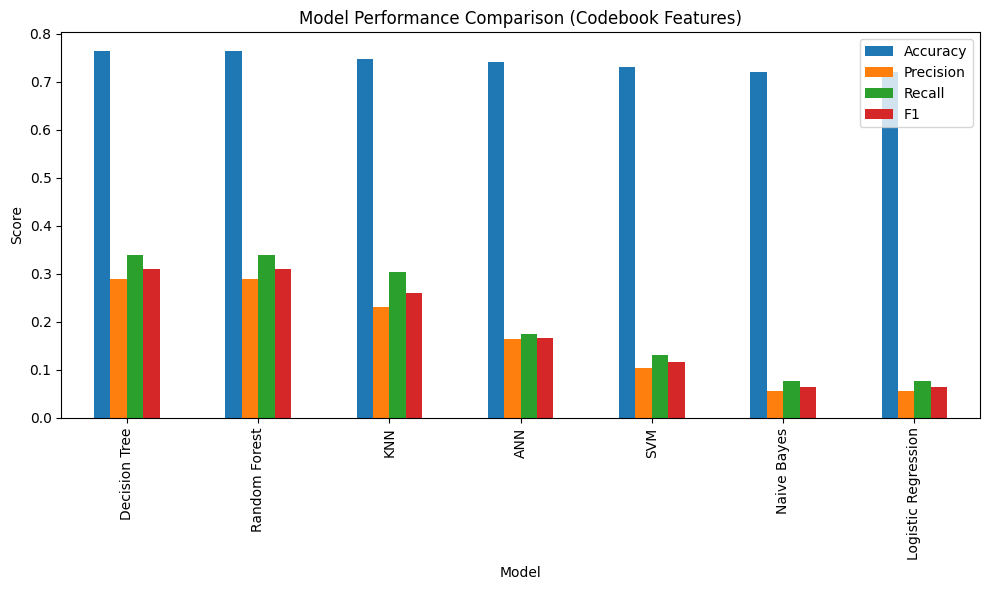

In [205]:
# Codebook Model Comparison Plot

codebook_results_sorted = codebook_results.sort_values(
    by="Accuracy",
    ascending=False
)

codebook_results_sorted.to_csv(
    "CODEBOOK_MODEL_RESULTS.csv",
    index=False
)

codebook_results_sorted.set_index(
    "Model"
)[
    ["Accuracy","Precision","Recall","F1"]
].plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Model Performance Comparison (Codebook Features)")

plt.ylabel("Score")

plt.tight_layout()

plt.savefig(
    "FIG11_CODEBOOK_MODEL_COMPARISON.png",
    dpi=300
)

plt.show()


Generating Confusion Matrix for KNN (Codebook)


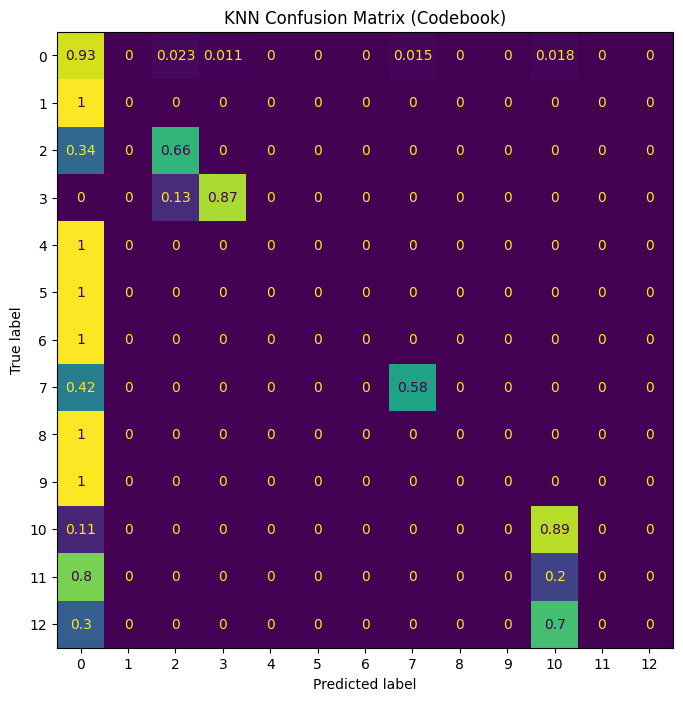

Generating Confusion Matrix for Decision Tree (Codebook)


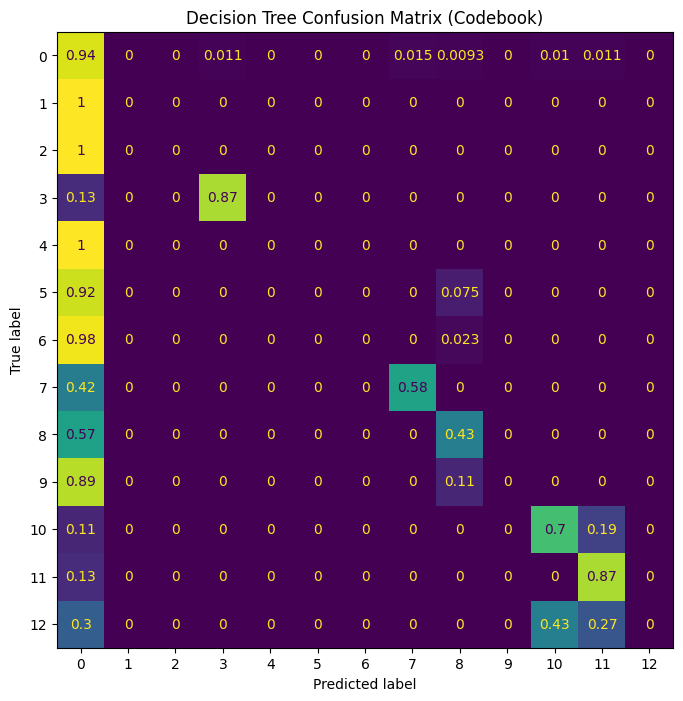

Generating Confusion Matrix for Random Forest (Codebook)


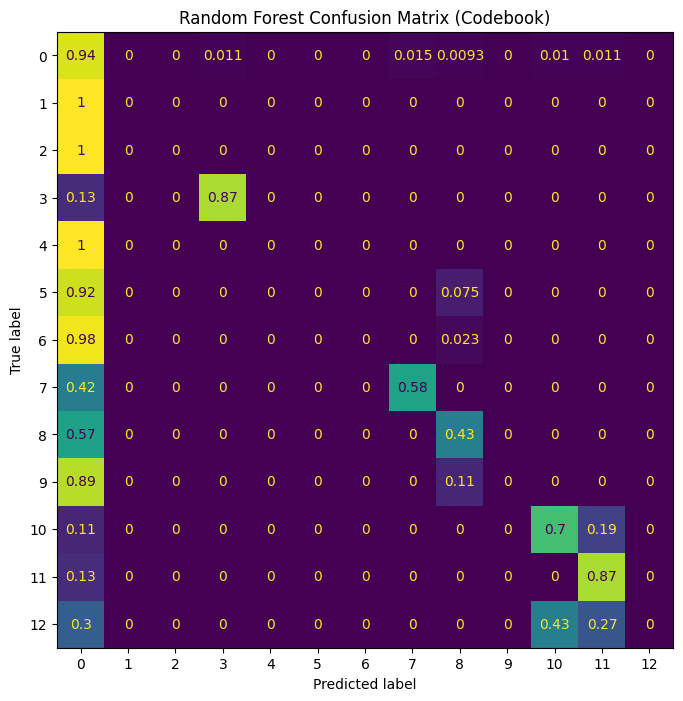

Generating Confusion Matrix for Naive Bayes (Codebook)


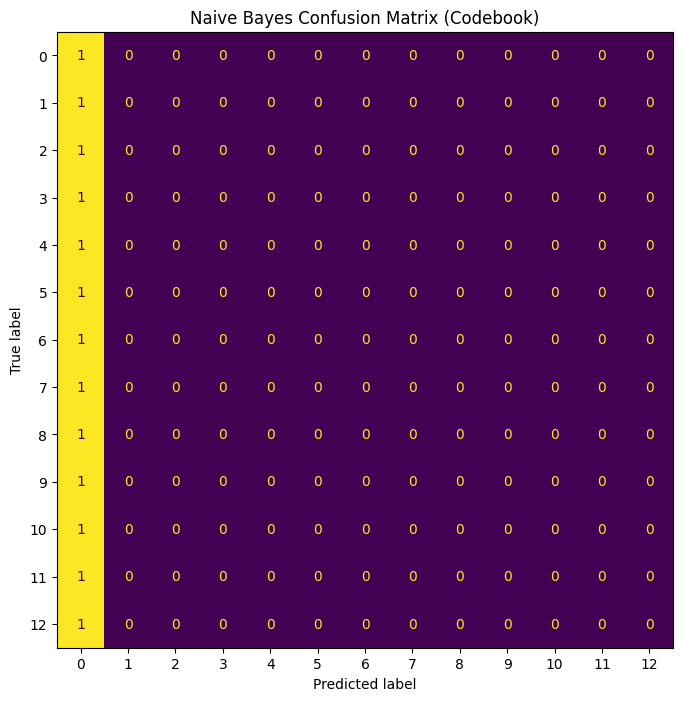

Generating Confusion Matrix for SVM (Codebook)


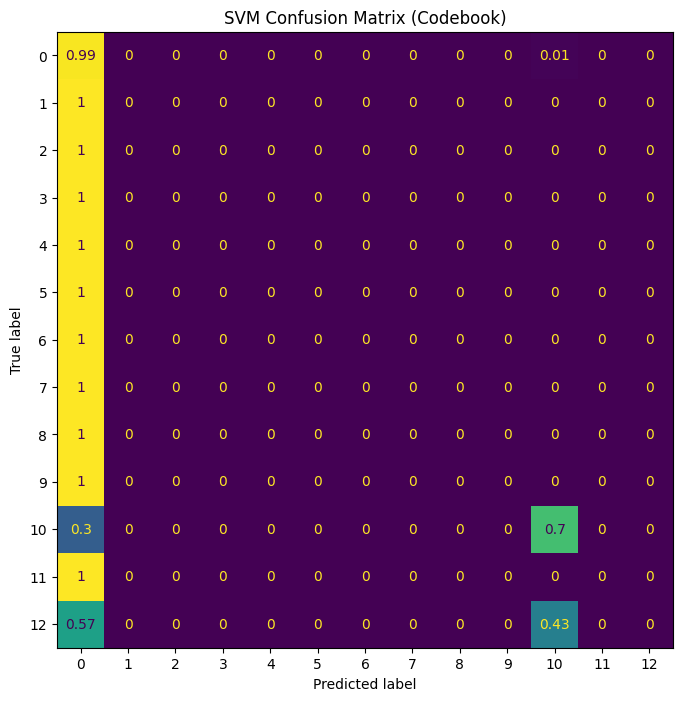

Generating Confusion Matrix for Logistic Regression (Codebook)


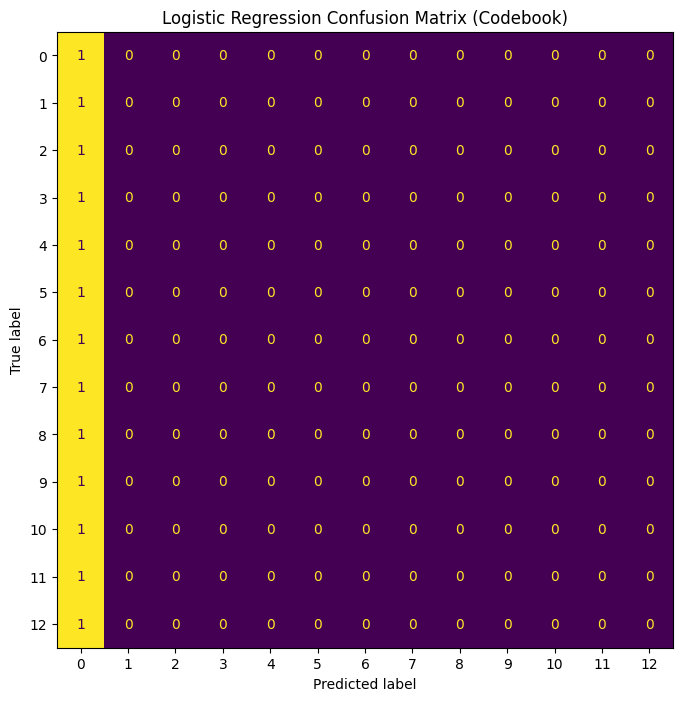

Generating Confusion Matrix for ANN (Codebook)


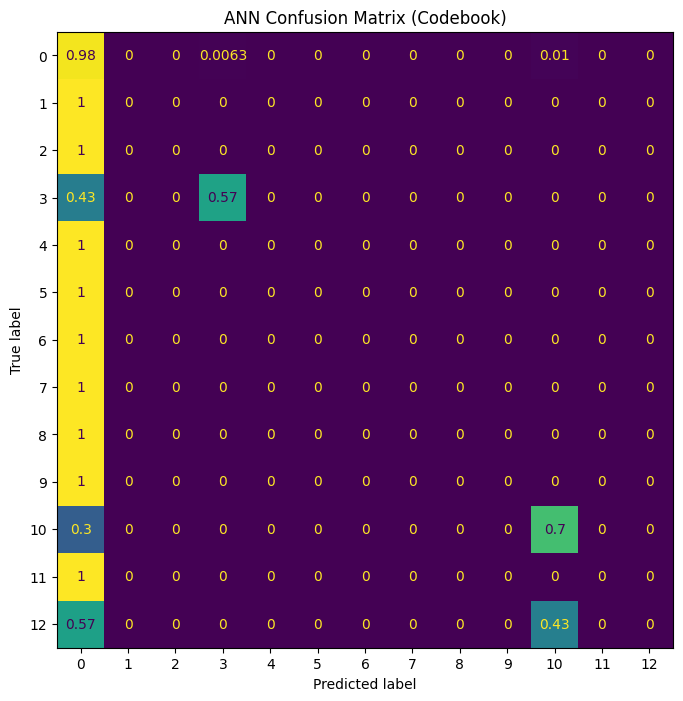

In [206]:
# Codebook Confusion Matrices for all Models (Codebook equivalent of FIG12)
# Reuses the models already trained in the loop above - no retraining needed

for name, model in fitted_models_cb.items():

    print(f"Generating Confusion Matrix for {name} (Codebook)")

    predictions = model.predict(
        X_test
    )

    cm = confusion_matrix(
        y_test,
        predictions,
        normalize='true'
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm
    )

    fig, ax = plt.subplots(
        figsize=(8,8)
    )

    disp.plot(
        ax=ax,
        colorbar=False
    )

    plt.title(
        f"{name} Confusion Matrix (Codebook)"
    )

    plt.savefig(
        f"FIG12_CODEBOOK_{name.replace(' ','_')}_CONFUSION_MATRIX.png",
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()


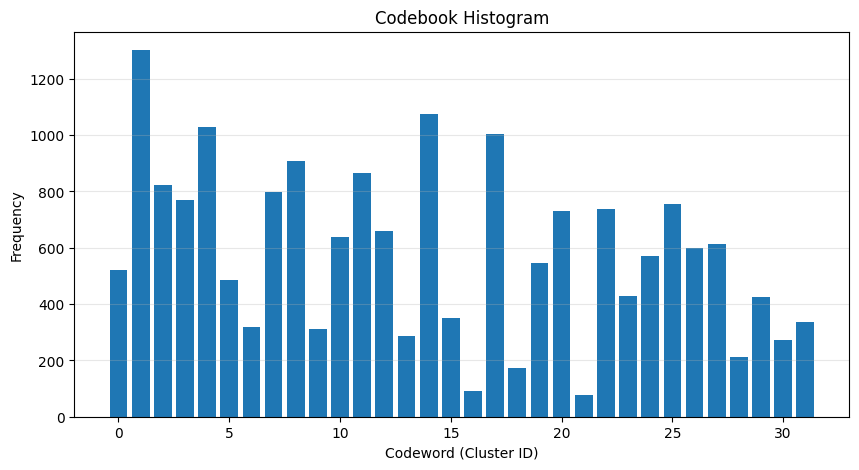

In [207]:
import matplotlib.pyplot as plt
import pandas as pd

cluster_counts = pd.Series(
    cluster_labels
).value_counts().sort_index()

plt.figure(figsize=(10,5))

plt.bar(
    cluster_counts.index,
    cluster_counts.values
)

plt.xlabel("Codeword (Cluster ID)")
plt.ylabel("Frequency")

plt.title(
    "Codebook Histogram"
)

plt.grid(
    axis='y',
    alpha=0.3
)

plt.savefig(
    "FIG10_CODEBOOK_HISTOGRAM.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Codebook Histogram

The histogram shows the frequency distribution of generated codewords (clusters) across all activity windows. Each bar represents the number of windows assigned to a specific codeword generated using MiniBatchKMeans.

# Codebook Histogram per Activity

Grouped bar chart showing the codeword (cluster) histogram for each activity class, allowing comparison of codebook usage patterns across activities.

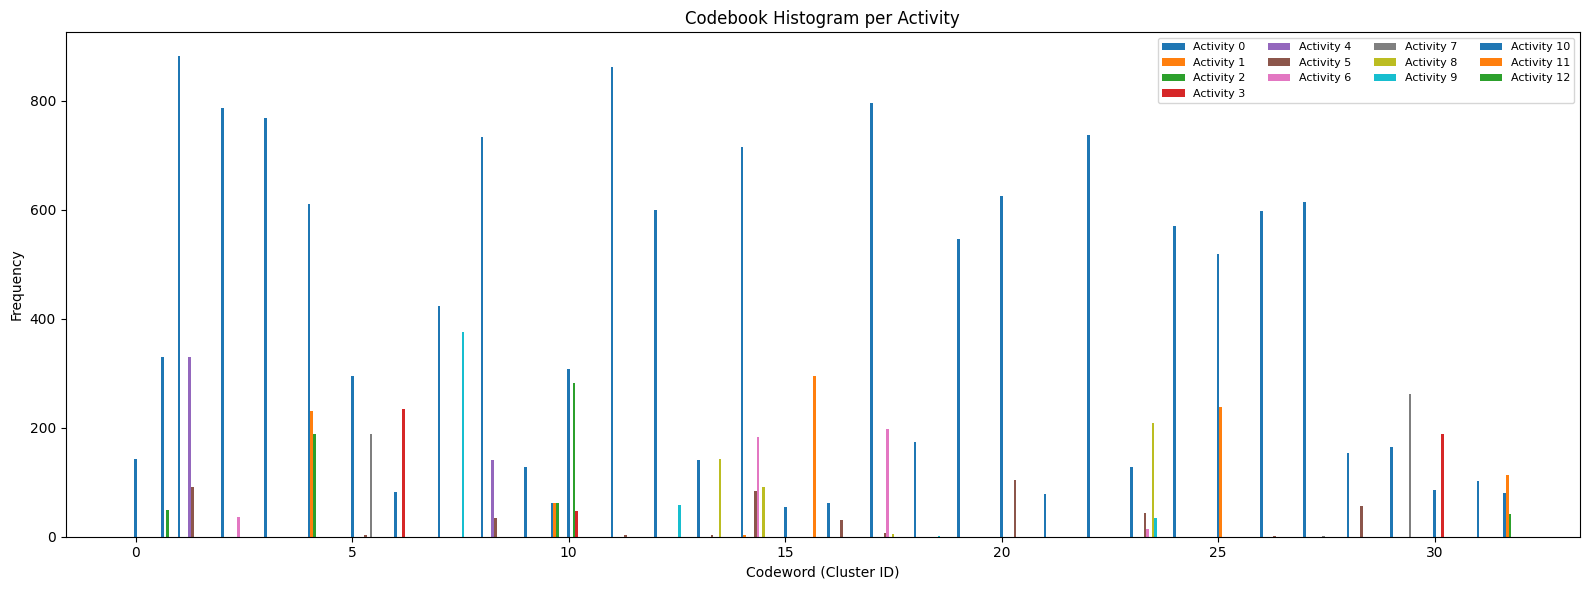

In [208]:
# Codebook Histogram per Activity , Fig10

unique_activities_cb = sorted(codebook_df['Activity'].unique())

n_clusters = kmeans.n_clusters

hist_matrix = np.zeros((len(unique_activities_cb), n_clusters))

for i, act in enumerate(unique_activities_cb):

    sub = codebook_df[codebook_df['Activity'] == act]['cluster_id']

    counts = sub.value_counts().reindex(
        range(n_clusters),
        fill_value=0
    )

    hist_matrix[i] = counts.values

x = np.arange(n_clusters)

width = 0.8 / len(unique_activities_cb)

plt.figure(figsize=(16,6))

for i, act in enumerate(unique_activities_cb):

    plt.bar(
        x + i * width,
        hist_matrix[i],
        width=width,
        label=f"Activity {act}"
    )

plt.xlabel("Codeword (Cluster ID)")
plt.ylabel("Frequency")

plt.title("Codebook Histogram per Activity")

plt.legend(ncol=4, fontsize=8)

plt.tight_layout()

plt.savefig(
    "FIG10_CODEBOOK_HISTOGRAM_PER_ACTIVITY.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# Combined Feature Set (Time + Spectral) and Best Model Summary (FIG13)

1. Build a combined feature set (Time-Domain selected features + Spectral features)
2. Scale, PCA (95% variance), split, and train all 7 models
3. Compare the best model from each feature family (Time, Spectral, Codebook, Combined) using a radar chart

In [209]:
# Combined Feature Set: Time-Domain (X_final) + Spectral (X_spec)

combined_X = pd.concat(
    [
        X_final.reset_index(drop=True),
        X_spec.reset_index(drop=True)
    ],
    axis=1
)

combined_y = y.reset_index(drop=True)

print("Combined Feature Shape:", combined_X.shape)

scaler_comb = StandardScaler()

X_comb_scaled = scaler_comb.fit_transform(combined_X)

pca_comb = PCA(n_components=0.95)

X_comb_pca = pca_comb.fit_transform(X_comb_scaled)

print("Combined PCA Shape:", X_comb_pca.shape)
print("Components Used:", pca_comb.n_components_)


Combined Feature Shape: (18709, 244)
Combined PCA Shape: (18709, 81)
Components Used: 81


In [210]:
# Train/Test Split + Train all models on Combined Features

X_train_comb, X_test_comb, y_train_comb, y_test_comb = train_test_split(
    X_comb_pca,
    combined_y,
    test_size=0.20,
    random_state=42,
    stratify=combined_y
)

models_comb = {

    "KNN":
        KNeighborsClassifier(),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ),

    "Naive Bayes":
        GaussianNB(),

    "SVM":
        SVC(),

    "Logistic Regression":
        LogisticRegression(
            max_iter=5000
        ),

    "ANN":
        MLPClassifier(
            hidden_layer_sizes=(100,),
            max_iter=500,
            random_state=42
        )
}

results_comb = []

fitted_models_comb = {}

for name, model in models_comb.items():

    print(f"Training {name} (Combined)...")

    model.fit(
        X_train_comb,
        y_train_comb
    )

    fitted_models_comb[name] = model

    predictions = model.predict(
        X_test_comb
    )

    accuracy = accuracy_score(
        y_test_comb,
        predictions
    )

    precision = precision_score(
        y_test_comb,
        predictions,
        average='macro'
    )

    recall = recall_score(
        y_test_comb,
        predictions,
        average='macro'
    )

    f1 = f1_score(
        y_test_comb,
        predictions,
        average='macro'
    )

    results_comb.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

combined_results = pd.DataFrame(
    results_comb,
    columns=["Model","Accuracy","Precision","Recall","F1"]
)

combined_results = combined_results.sort_values(
    by="Accuracy",
    ascending=False
)

combined_results.to_csv(
    "COMBINED_MODEL_RESULTS.csv",
    index=False
)

combined_results


Training KNN (Combined)...
Training Decision Tree (Combined)...
Training Random Forest (Combined)...
Training Naive Bayes (Combined)...
Training SVM (Combined)...
Training Logistic Regression (Combined)...
Training ANN (Combined)...


,Model,Accuracy,Precision,Recall,F1
4,SVM,0.902726,0.809120,0.873581,0.832841
2,Random Forest,0.899786,0.867287,0.775641,0.796331
5,Logistic Regression,0.898450,0.799930,0.862819,0.829067
6,ANN,0.894441,0.805879,0.819070,0.812172
0,KNN,0.878407,0.748251,0.884347,0.806438
1,Decision Tree,0.846606,0.732522,0.708104,0.718068
3,Naive Bayes,0.758952,0.602162,0.898874,0.701792


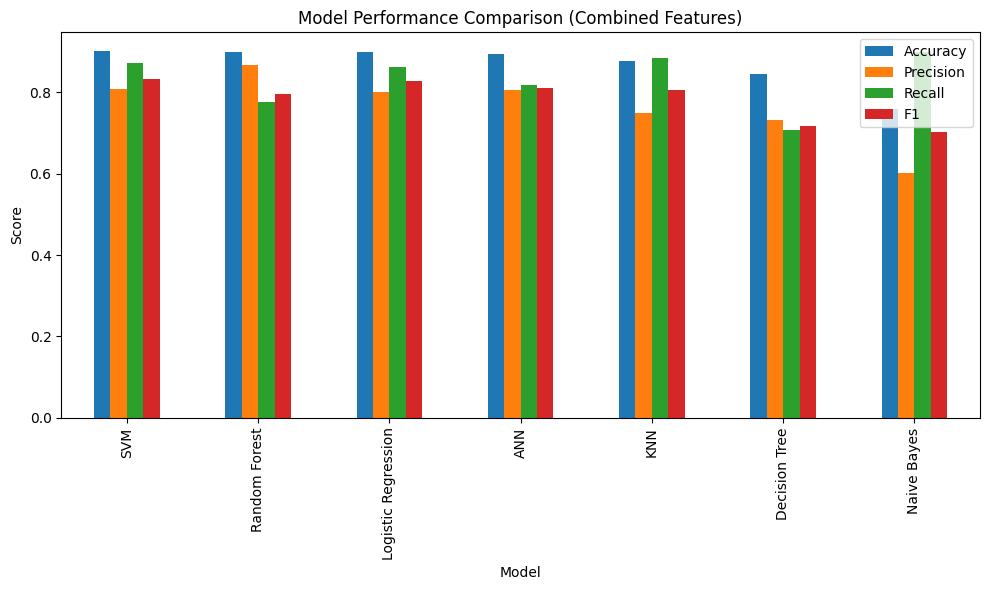

Generating Confusion Matrix for KNN (Combined)


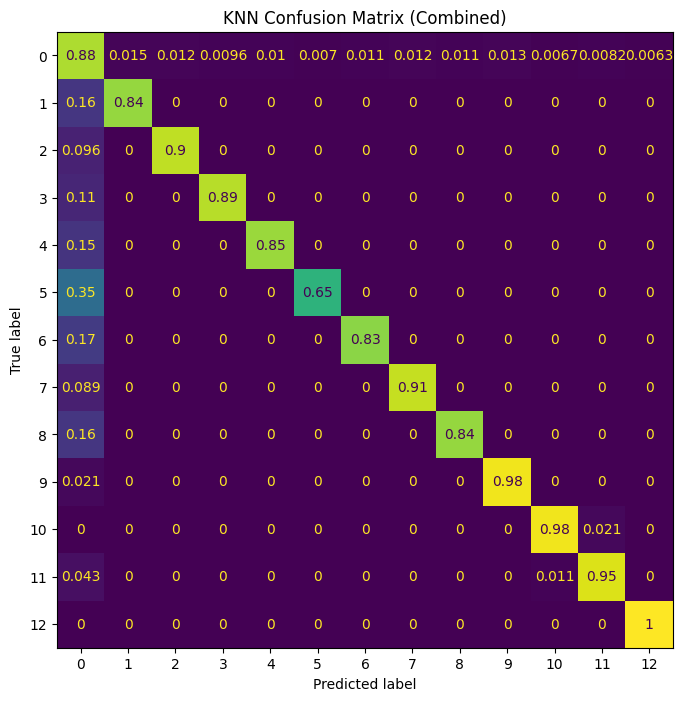

Generating Confusion Matrix for Decision Tree (Combined)


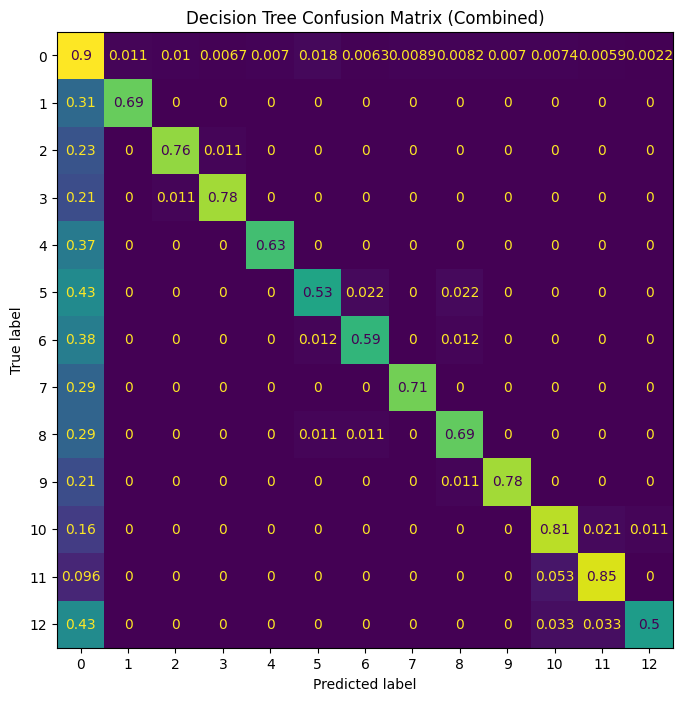

Generating Confusion Matrix for Random Forest (Combined)


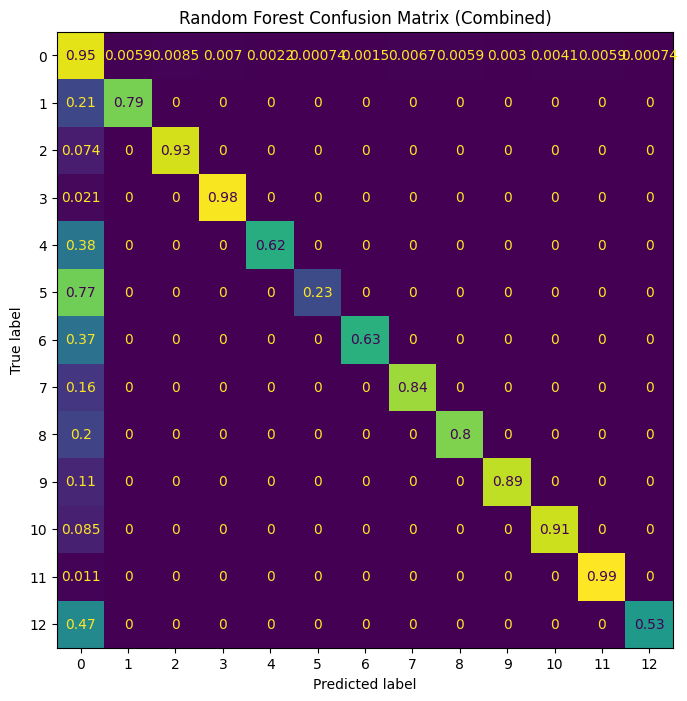

Generating Confusion Matrix for Naive Bayes (Combined)


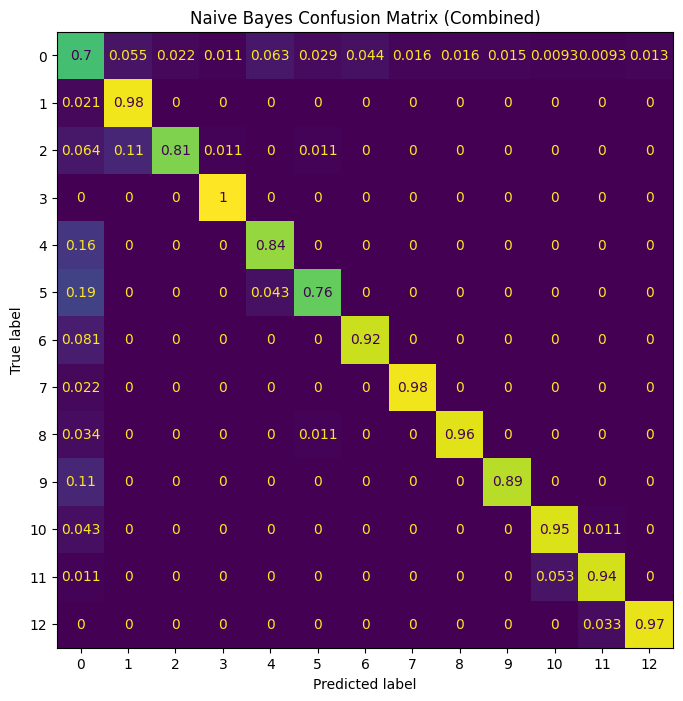

Generating Confusion Matrix for SVM (Combined)


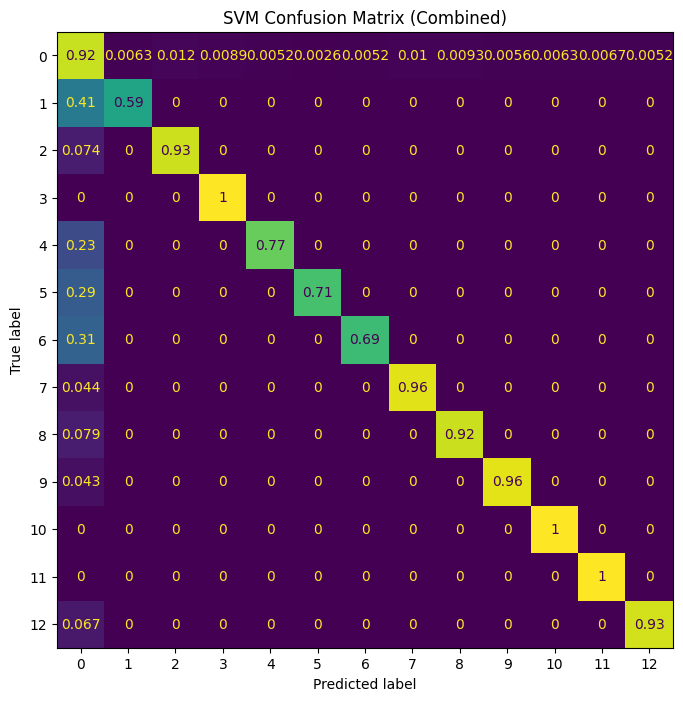

Generating Confusion Matrix for Logistic Regression (Combined)


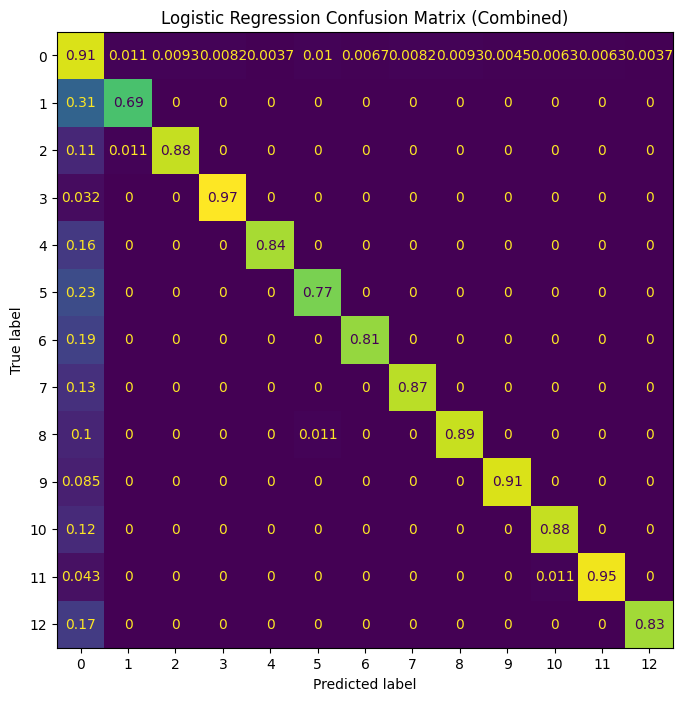

Generating Confusion Matrix for ANN (Combined)


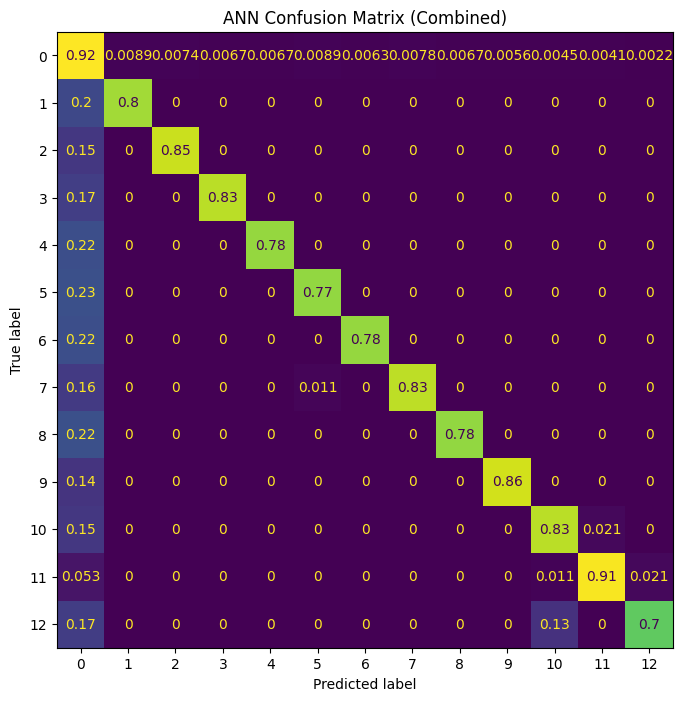

In [211]:
# Combined Model Comparison Plot + Confusion Matrices

combined_results.set_index(
    "Model"
)[
    ["Accuracy","Precision","Recall","F1"]
].plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Model Performance Comparison (Combined Features)")
plt.ylabel("Score")
plt.tight_layout()

plt.savefig(
    "FIG11_COMBINED_MODEL_COMPARISON.png",
    dpi=300
)

plt.show()

for name, model in fitted_models_comb.items():

    print(f"Generating Confusion Matrix for {name} (Combined)")

    predictions = model.predict(X_test_comb)

    cm = confusion_matrix(
        y_test_comb,
        predictions,
        normalize='true'
    )

    disp = ConfusionMatrixDisplay(confusion_matrix=cm)

    fig, ax = plt.subplots(figsize=(8,8))

    disp.plot(ax=ax, colorbar=False)

    plt.title(f"{name} Confusion Matrix (Combined)")

    plt.savefig(
        f"FIG12_COMBINED_{name.replace(' ','_')}_CONFUSION_MATRIX.png",
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()


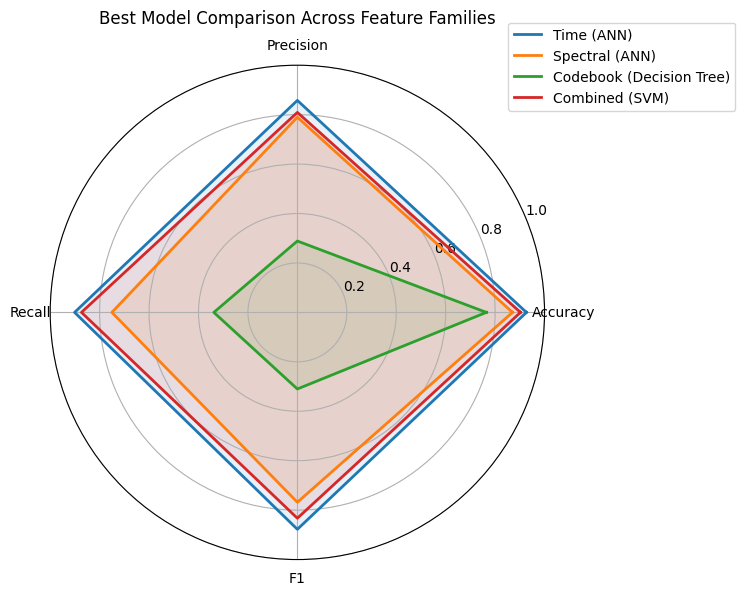

In [212]:
# FIG13: Best Model Summary Across Feature Families (Radar Chart)

best_time = results_df.sort_values(
    by="Accuracy", ascending=False
).iloc[0]

best_spectral = spectral_results.sort_values(
    by="Accuracy", ascending=False
).iloc[0]

best_codebook = codebook_results.sort_values(
    by="Accuracy", ascending=False
).iloc[0]

best_combined = combined_results.sort_values(
    by="Accuracy", ascending=False
).iloc[0]

categories = ["Accuracy","Precision","Recall","F1"]

families = {
    f"Time ({best_time['Model']})": best_time[categories].astype(float).values,
    f"Spectral ({best_spectral['Model']})": best_spectral[categories].astype(float).values,
    f"Codebook ({best_codebook['Model']})": best_codebook[categories].astype(float).values,
    f"Combined ({best_combined['Model']})": best_combined[categories].astype(float).values,
}

angles = np.linspace(0, 2*np.pi, len(categories), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8,8), subplot_kw=dict(polar=True))

for label, values in families.items():

    vals = list(values) + [values[0]]

    ax.plot(angles, vals, linewidth=2, label=label)
    ax.fill(angles, vals, alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)
ax.set_ylim(0, 1)

ax.set_title("Best Model Comparison Across Feature Families", pad=30)

ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.1))

plt.tight_layout()

plt.savefig(
    "FIG13_BEST_MODEL_RADAR.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()
